wrote fmm_figures/fig_master_curve_combined.pdf and fmm_figures/fig_master_curve_combined.png


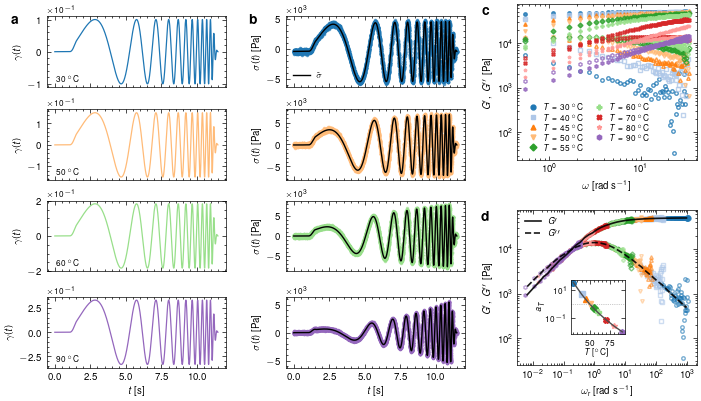

In [3]:
"""
plot_master_curve_standalone_combined.py
=========================================
Three-column master-curve figure, built ONLY from the files written by
`export_master_curve()` (a `<path>.npz` + `<path>.json` pair). No import
of `paper_utils`, `rheogp`, or `torch` anywhere in this file -- copy it
next to your exported data on any machine that has numpy + matplotlib
(+ optionally `scienceplots`) and run it.

This is the COMBINED variant: storage (G') and loss (G'') share ONE
panel in column 3's top half (filled markers = G', open markers = G''),
instead of getting split into separate panels. See
plot_master_curve_standalone_split.py for the two-panel version.

Layout
------
    col 1                 col 2                  col 3
    strain gamma(t)       stress sigma(t)         (top)    unshifted FFT
    one row per T shown   measured + predicted             spectrum, all T
    ...                   ...                     (bottom) shifted FFT +
                                                             GPR analytic
                                                             master curve
                                                             + posterior-
                                                             predictive FFT
                                                             ensemble band,
                                                             with an inset
                                                             of a_T vs T

Only a representative subset of temperatures is drawn in columns 1-2
(set N_SHOW below); column 3 uses every record, since the point of that
panel is the TTS collapse itself. Every temperature gets its own fixed
(color, marker) pair, used consistently across every panel of the
figure (including the measured-stress markers in column 2, which share
the strain color for that row -- only the model's prediction stays
black), listed once in a legend -- no colorbar. Each strain/stress
row's y-axis carries its own independent x10^n offset notation, since
one row's stress range can be orders of magnitude away from the next.

Column 3 is built as its OWN nested grid spanning the full column
height (`outer[:, 2]`), independent of the row indices columns 1-2 use
-- NOT sliced by row range (`outer[0:n_top, 2]` / `outer[n_top:, 2]`)
like an earlier version of this script did. Tying column 3's internal
split to the same row boundaries as columns 1-2 forces
`constrained_layout` to reconcile column 3's spacing needs at that
specific row boundary across EVERY column, which showed up as a
visibly bigger gap between two of the strain/stress rows even though
those rows didn't need the extra space themselves. Nesting a nested
GridSpecFromSubplotSpec inside a single spanning cell avoids that
forced cross-column alignment entirely.

The master-curve panel can show either or both of two DIFFERENT
uncertainty estimates -- pick with the single `MASTER_CURVE_SOURCE`
setting below ("analytic", "posterior", or "both"):
  * the analytic Gstar curve+band (from `_model_curve_from_mj` in
    paper_utils.py) -- a credible interval on the *mean* prefactor,
    which shrinks as more data is pooled and can look implausibly tight
    next to noisy raw data;
  * the posterior-predictive FFT ensemble curve+band (from
    `_posterior_fft_ensemble`, `postfft_*` arrays) -- built by drawing
    correlated posterior samples of the fitted stress trace and
    FFT-transforming each one, so its spread reflects the model's
    actual predictive uncertainty in the frequency domain.
They are not the same quantity, so "both" is the default for
comparison, but either can be selected on its own.

Edit the "USER SETTINGS" block below and run:  python3 plot_master_curve_standalone_combined.py
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ----------------------------------------------------------------
# USER SETTINGS
# ----------------------------------------------------------------
# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
EXPORT_PATH = f"{DATA_DIR}/fmm_export"      # base path -> reads fmm_export.npz + fmm_export.json
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/fig_master_curve_combined"  # writes <OUT_NAME>.pdf and <OUT_NAME>.png next to this script
N_SHOW = 4                      # how many temperatures to draw in columns 1-2
SHOW_PREDICTED_BAND = True      # +/- 2 sigma band on the predicted stress
SHOW_TRUTH_SHIFT_FACTORS = True # overlay shift_factors_truth in the inset, if present

# Which master-curve estimate(s) to draw in the bottom spectrum panel,
# each with its own credible band -- the single switch for what used to
# be two independent flags:
#   "analytic"  -- only the analytic Gstar curve (tight: a CI on the mean
#                  prefactor, from _model_curve_from_mj in paper_utils.py)
#   "posterior" -- only the posterior-predictive FFT ensemble (wider:
#                  reflects actual predictive uncertainty, from
#                  _posterior_fft_ensemble / postfft_* arrays)
#   "both"      -- draw both, clearly labeled, for comparison
MASTER_CURVE_SOURCE = "posterior"
N_FREQ_BINS = 40                # log-spaced bins used to summarize the FFT ensemble

# Column-3 internal proportions: [combined spectrum row, master-curve row]
COL3_HEIGHT_RATIOS = [1.0, 1.0]


# ----------------------------------------------------------------
# Inline reload of an export_master_curve() bundle -- pure numpy + json,
# duplicated here on purpose so this script has zero local imports.
# ----------------------------------------------------------------
def load_export(path):
    from types import SimpleNamespace

    with open(f"{path}.json") as fh:
        meta = json.load(fh)
    data = np.load(f"{path}.npz")
    arrays = {k: data[k] for k in data.files}

    def record(i):
        pfx = f"rec{i}_"
        return {k[len(pfx):]: v for k, v in arrays.items() if k.startswith(pfx)}

    model_curve = None
    if "model_curve_omega" in arrays:
        model_curve = (
            arrays["model_curve_omega"], arrays["model_curve_Gp"],
            arrays["model_curve_Gdp"], arrays.get("model_curve_Gp_ci"),
            arrays.get("model_curve_Gdp_ci"),
        )

    return SimpleNamespace(meta=meta, arrays=arrays, record=record,
                            n_records=meta["n_records"], model_curve=model_curve)


# ----------------------------------------------------------------
# Style (matches the paper's other figures)
# ----------------------------------------------------------------
try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})

TAB10 = plt.cm.tab20.colors  # discrete colors, cycled per record
MARKERS = ["o", "s", "^", "v", "D", "P", "X", "*", "h", "8"]  # cycled per record
COLOR_PRED = "black"       # predicted stress line + band -- stays fixed, not per-record
COLOR_MASTER = "k"         # analytic + ensemble master-curve lines
COLOR_ANALYTIC_BAND = "0.6"     # analytic Gstar credible band (gray)
COLOR_POSTFFT_BAND = "tab:orange"  # posterior-predictive FFT ensemble band


def add_panel_letter(ax, text, xoff=-20, yoff=0, fontsize=10):
    """Bold panel letter just outside the top-left of an axes, offset in
    POINTS (not axes-fraction) so it stays put regardless of that
    panel's own size -- same convention/size as the paper's other
    multi-panel figures."""
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


def record_style(i):
    """Fixed (color, marker) pair per record index -- same identity in
    every panel of the figure, so a color+marker combo always means the
    same temperature no matter which column you're looking at."""
    return TAB10[i % len(TAB10)], MARKERS[i % len(MARKERS)]


def use_sci_y(ax, fontsize=6):
    """Force a scientific-notation x10^n offset on this axis's own y
    ticks (independent of any other axis), so a row with values ~1e-2
    doesn't render long decimal tick labels next to a row with ~1e3."""
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(fontsize)


def summarize_ensemble(omega, values, n_bins=40):
    """Bin a (possibly huge) scatter cloud of (omega, value) points from
    the posterior-predictive FFT ensemble into log-spaced frequency bins
    and return the per-bin median + 95% interval. Returns None if there
    is nothing usable to summarize."""
    omega = np.asarray(omega, float)
    values = np.asarray(values, float)
    valid = np.isfinite(omega) & (omega > 0) & np.isfinite(values)
    omega, values = omega[valid], values[valid]
    if omega.size < 5:
        return None
    edges = np.logspace(np.log10(omega.min()), np.log10(omega.max()), n_bins + 1)
    centers = np.sqrt(edges[:-1] * edges[1:])
    med = np.full(n_bins, np.nan)
    lo = np.full(n_bins, np.nan)
    hi = np.full(n_bins, np.nan)
    idx = np.clip(np.digitize(omega, edges) - 1, 0, n_bins - 1)
    for b in range(n_bins):
        sel = values[idx == b]
        if sel.size >= 5:
            med[b] = np.median(sel)
            lo[b] = np.quantile(sel, 0.025)
            hi[b] = np.quantile(sel, 0.975)
    keep = np.isfinite(med)
    if not keep.any():
        return None
    return centers[keep], med[keep], lo[keep], hi[keep]


def render_master_curve(EXPORT_PATH=EXPORT_PATH, OUT_NAME=OUT_NAME):
    """Draw the figure for ONE `export_master_curve()` bundle.

    The body below is wrapped in a function purely so the SAME
    figure can be drawn for more than one bundle without
    duplicating it: the per-noise-level cell at the end of this
    notebook calls it once per noise level, against the bundles
    Sec. 9 of `01_synthetic_fmm_tts.ipynb` writes. Called with no
    arguments it uses the USER SETTINGS above, exactly as this
    script did when the body was bare module-level code.

    Every other setting (N_SHOW, MASTER_CURVE_SOURCE, ...) is still
    read from module level, so editing the block above changes both
    the headline figure and every per-noise one.
    """
    # ----------------------------------------------------------------
    # Load data
    # ----------------------------------------------------------------
    data = load_export(EXPORT_PATH)
    T = np.asarray(data.arrays["temperatures"], float)
    n_rec = data.n_records

    # a representative, evenly spaced subset of temperatures for columns 1-2
    n_show = min(N_SHOW, n_rec)
    show_idx = np.unique(np.round(np.linspace(0, n_rec - 1, n_show)).astype(int))
    n_show = len(show_idx)

    i_ref = int(data.meta.get("i_ref", 0))

    # ----------------------------------------------------------------
    # Figure / GridSpec: n_show rows for cols 1-2. Column 3 is ONE spanning
    # cell (outer[:, 2]) subdivided independently -- see the module
    # docstring for why this avoids a forced cross-column spacing conflict.
    # ----------------------------------------------------------------
    fig = plt.figure(figsize=(7.0, 4))
    outer = gridspec.GridSpec(n_show, 3, figure=fig, width_ratios=[1.0, 1.0, 1.25],
                               wspace=0.1, hspace=0.06)

    gs_col3 = gridspec.GridSpecFromSubplotSpec(
        2, 1, subplot_spec=outer[:, 2], height_ratios=COL3_HEIGHT_RATIOS, hspace=0.1)
    ax_spec_top = fig.add_subplot(gs_col3[0])  # combined storage+loss spectrum, unshifted
    ax_spec_bot = fig.add_subplot(gs_col3[1])  # shifted spectra + master curve

    # ----------------------------------------------------------------
    # Columns 1-2: strain and stress vs time, one row per selected temperature
    # ----------------------------------------------------------------
    ax_strain0 = None
    ax_stress0 = None
    for row, i in enumerate(show_idx):
        rec = data.record(int(i))
        Ti = T[i]
        c, mk = record_style(int(i))

        ax_g = fig.add_subplot(outer[row, 0], sharex=ax_strain0)
        ax_s = fig.add_subplot(outer[row, 1], sharex=ax_stress0)
        if ax_strain0 is None:
            ax_strain0, ax_stress0 = ax_g, ax_s

        ax_g.plot(rec["t"], rec["gamma"], color=c, lw=0.9)
        ax_g.set_ylabel(r"$\gamma(t)$")
        ax_g.text(0.05, 0.06, f"${Ti:g}~^\circ\mathrm{{C}}$", transform=ax_g.transAxes,
                  fontsize=6, ha="left", va="bottom", color="black")
        use_sci_y(ax_g)
        # measured stress follows the same per-record color as strain;
        # the model's prediction stays black regardless of temperature.
        ax_s.plot(rec["t"], rec["sigma"], color=c, lw=0.0,
                  marker="o", ms=1.6, alpha=0.6)
        ax_s.plot(rec["t"], rec["pred"], color=COLOR_PRED, lw=1.0,
                  label=r"$\bar{\sigma}$" if row == 0 else None)
        if SHOW_PREDICTED_BAND and "pred_std" in rec:
            ax_s.fill_between(rec["t"], rec["pred"] - 2 * rec["pred_std"],
                              rec["pred"] + 2 * rec["pred_std"],
                              color=COLOR_PRED, alpha=0.20, lw=0)
        ax_s.set_ylabel(r"$\sigma(t)$ [Pa]")
        use_sci_y(ax_s)

        if row == n_show - 1:
            ax_g.set_xlabel(r"$t$ [s]")
            ax_s.set_xlabel(r"$t$ [s]")
        else:
            plt.setp(ax_g.get_xticklabels(), visible=False)
            plt.setp(ax_s.get_xticklabels(), visible=False)

        if row == 0:
            add_panel_letter(ax_g, r"$\mathbf{a}$", yoff=2)
            add_panel_letter(ax_s, r"$\mathbf{b}$", yoff=2)

    ax_stress0.legend(frameon=False, loc="best")

    # ----------------------------------------------------------------
    # Column 3, top: unshifted FFT spectra, storage (G') and loss (G'')
    # overlaid in ONE panel -- filled markers = G', open markers = G''
    # ----------------------------------------------------------------
    for i in range(n_rec):
        rec = data.record(i)
        c, mk = record_style(i)
        ax_spec_top.loglog(rec["fft_omega"], rec["fft_Gp"], marker=mk, ms=2.5,
                           ls="none", mfc=c, mec=c, alpha=0.8)
        ax_spec_top.loglog(rec["fft_omega"], rec["fft_Gdp"], marker=mk, ms=2.5,
                           ls="none", mfc="none", mec=c, alpha=0.8)
    ax_spec_top.set_ylabel(r"$G',\,G''$ [Pa]")
    ax_spec_top.set_xlabel(r"$\omega~[\mathrm{rad~s}^{-1}]$")
    add_panel_letter(ax_spec_top, r"$\mathbf{c}$")

    temp_handles = [plt.Line2D([], [], marker=record_style(i)[1], ls="none",
                               mfc=record_style(i)[0], mec=record_style(i)[0], ms=3.5,
                               label=f"$T={T[i]:g}~^\circ\mathrm{{C}}$")
                   for i in range(n_rec)]
    ax_spec_top.legend(handles=temp_handles, frameon=False, loc="best",
                       ncol=1 if n_rec <= 6 else 2,
                       columnspacing=0.8, handletextpad=0.3, labelspacing=0.3)

    # ----------------------------------------------------------------
    # Column 3, bottom: shifted FFT spectra + analytic master curve +
    # posterior-predictive FFT ensemble band
    # ----------------------------------------------------------------
    for i in range(n_rec):
        rec = data.record(i)
        c, mk = record_style(i)
        ax_spec_bot.loglog(rec["fft_omega_reduced"], rec["fft_Gp"], marker=mk, ms=2.5,
                           ls="none", mfc=c, mec=c, alpha=0.6)
        ax_spec_bot.loglog(rec["fft_omega_reduced"], rec["fft_Gdp"], marker=mk, ms=2.5,
                           ls="none", mfc="none", mec=c, alpha=0.6)

    handles, labels = [], []


    def _valid_band(ci):
        # ci is None if it was never exported; NaN-filled if every posterior
        # draw produced a non-finite/non-positive prefactor (bad fit) -- in
        # both cases fill_between would silently draw nothing, so check
        # explicitly rather than let the band vanish without a trace.
        return ci is not None and np.any(np.isfinite(ci))


    show_posterior = MASTER_CURVE_SOURCE in ("posterior", "both")
    show_analytic = MASTER_CURVE_SOURCE in ("analytic", "both")

    # -- posterior-predictive FFT ensemble: median + band together (wider,
    #    reflects actual predictive uncertainty rather than uncertainty in
    #    the mean prefactor). Solid = G', dashed = G'' -- both get a legend
    #    entry (\bar{G'}/\bar{G''}, the "posterior mean" notation), handles
    #    and labels appended IN LOCKSTEP so a later "both" run doesn't
    #    silently shift every subsequent label by one slot (ax.legend(handles,
    #    labels) zips to the SHORTER list with no warning if they go out of
    #    sync).
    if show_posterior and "postfft_omega_reduced" in data.arrays \
            and data.arrays["postfft_omega_reduced"].size:
        pf_omega = data.arrays["postfft_omega_reduced"]
        for name, values, ls, bar_label in (
                ("$G'$", data.arrays["postfft_Gp"], "-", r"$\bar{G'}$"),
                ("$G''$", data.arrays["postfft_Gdp"], "--", r"$\bar{G''}$")):
            summary = summarize_ensemble(pf_omega, values, n_bins=N_FREQ_BINS)
            if summary is None:
                print(f"  (posterior-FFT ensemble for {name}: not enough points to bin)")
                continue
            centers, med, lo, hi = summary
            ax_spec_bot.fill_between(centers, lo, hi, color="k",
                                     alpha=0.5, lw=0)
            h_med, = ax_spec_bot.loglog(centers, med, color="k", lw=1.2, ls=ls, alpha=0.9)
            handles.append(h_med)
            labels.append(bar_label)
    elif show_posterior:
        print("  (no posterior-predictive FFT ensemble in this export -- "
              "postfft_omega_reduced not found; re-export with include_posterior_fft=True)")

    # -- analytic Gstar: median + band together (tight: a CI on the mean prefactor)
    if show_analytic and data.model_curve is not None:
        omega_m, Gp_m, Gdp_m, Gp_ci, Gdp_ci = data.model_curve
        h_gp, = ax_spec_bot.loglog(omega_m, Gp_m, color=COLOR_MASTER, lw=1.2, ls="-")
        h_gdp, = ax_spec_bot.loglog(omega_m, Gdp_m, color=COLOR_MASTER, lw=1.2, ls="--")
        handles += [h_gp, h_gdp]
        labels += ["GPR $G'$ (analytic)", "GPR $G''$ (analytic)"]

        band_drawn = False
        if _valid_band(Gp_ci):
            ax_spec_bot.fill_between(omega_m, Gp_ci[0], Gp_ci[1], color=COLOR_ANALYTIC_BAND,
                                     alpha=0.35, lw=0)
            band_drawn = True
        else:
            print("  (no G' credible band: Gp_ci missing or all-NaN in the export)")
        if _valid_band(Gdp_ci):
            ax_spec_bot.fill_between(omega_m, Gdp_ci[0], Gdp_ci[1], color=COLOR_ANALYTIC_BAND,
                                     alpha=0.20, lw=0)
            band_drawn = True
        else:
            print("  (no G'' credible band: Gdp_ci missing or all-NaN in the export)")
        if band_drawn:
            handles.append(plt.matplotlib.patches.Patch(facecolor=COLOR_ANALYTIC_BAND, alpha=0.35, lw=0))
            labels.append("mean-prefactor 95\\% CI")
    elif show_analytic:
        print("  (no analytic master curve in this export -- model_curve_omega not found)")

    if handles:
        ax_spec_bot.legend(handles, labels, frameon=False, loc="best", fontsize=6)

    ax_spec_bot.set_ylabel(r"$G',\,G''$ [Pa]")
    ax_spec_bot.set_xlabel(r"$\omega_{\mathrm{r}}~[\mathrm{rad~s}^{-1}]$")
    add_panel_letter(ax_spec_bot, r"$\mathbf{d}$")

    # inset: shift factors vs temperature, same per-record color/marker identity
    ax_inset = ax_spec_bot.inset_axes([0.3, 0.2, 0.3, 0.35]) # x, y, w, h
    for i in range(n_rec):
        c, mk = record_style(i)
        ax_inset.plot(T[i], data.arrays["shift_factors"][i], marker=mk, ms=4,
                     ls="none", mfc=c, mec=c)
    if SHOW_TRUTH_SHIFT_FACTORS and "shift_factors_truth" in data.arrays:
        ax_inset.plot(T, data.arrays["shift_factors_truth"], "-",
                     color="0.3", label="truth")
        #ax_inset.legend(frameon=False, fontsize=6, loc="best")
    ax_inset.axhline(1.0, color="0.6", lw=0.5, ls=":")
    ax_inset.set_yscale("log")
    ax_inset.set_xlabel(r"$T~[^\circ\mathrm{C}]$", fontsize=6, labelpad=1)
    ax_inset.set_ylabel("$a_T$", fontsize=6, labelpad=1)
    ax_inset.tick_params(labelsize=6)

    # ----------------------------------------------------------------
    fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
    fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
    print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
    return fig


# The headline figure, from the USER SETTINGS above.
fig_master = render_master_curve()

4 noise level(s): 3% -> fmm_export/fmg_export_noise003, 8% -> fmm_export/fmg_export_noise008, 15% -> fmm_export/fmg_export_noise015, 25% -> fmm_export/fmg_export_noise025

--- noise 3%  (FractionalMaxwellGel, bundle fmm_export/fmg_export_noise003) ---
wrote fmm_figures/fig_master_curve_fmg_noise003.pdf and fmm_figures/fig_master_curve_fmg_noise003.png

--- noise 8%  (FractionalMaxwellGel, bundle fmm_export/fmg_export_noise008) ---
wrote fmm_figures/fig_master_curve_fmg_noise008.pdf and fmm_figures/fig_master_curve_fmg_noise008.png

--- noise 15%  (FractionalMaxwellGel, bundle fmm_export/fmg_export_noise015) ---
wrote fmm_figures/fig_master_curve_fmg_noise015.pdf and fmm_figures/fig_master_curve_fmg_noise015.png

--- noise 25%  (FractionalMaxwellGel, bundle fmm_export/fmg_export_noise025) ---
wrote fmm_figures/fig_master_curve_fmg_noise025.pdf and fmm_figures/fig_master_curve_fmg_noise025.png

wrote 4 figures: fmm_figures/fig_master_curve_fmg_noise003.pdf, fmm_figures/fig_master_curve_f

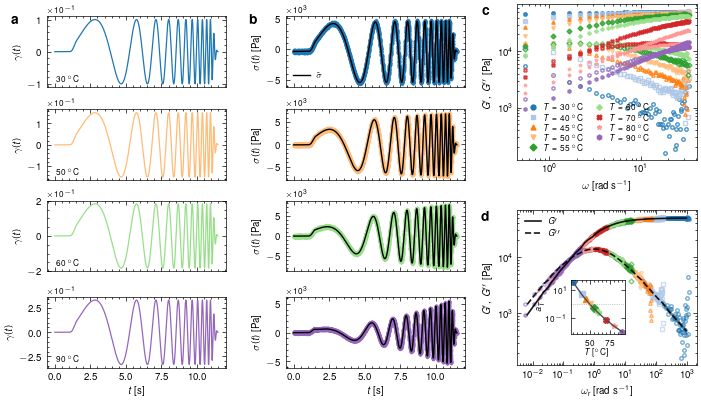

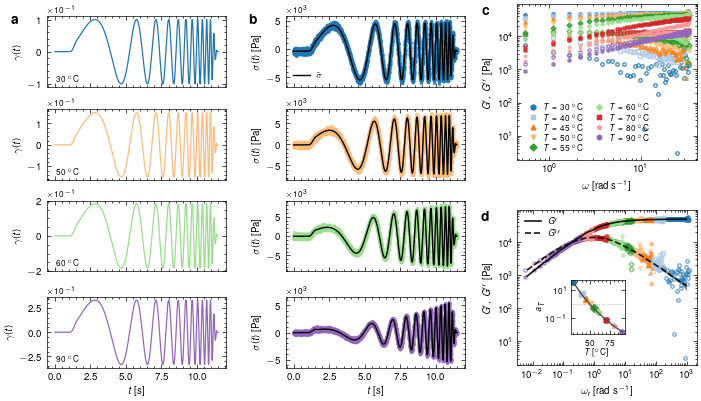

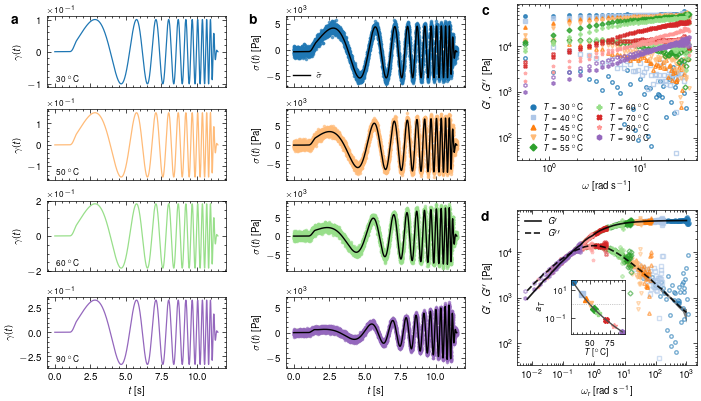

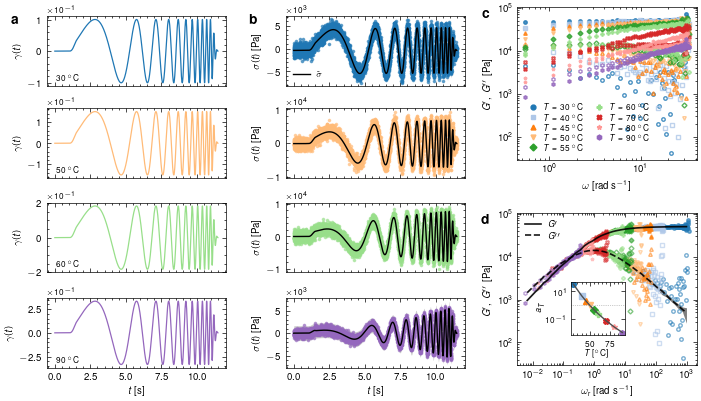

In [4]:
"""
plot_master_curve_per_noise.py
===============================
The same master-curve figure as the first cell of this notebook, drawn
once per injected noise level instead of once at the default one, from
the per-noise `export_master_curve()` bundles Sec. 9 of
`01_synthetic_fmm_tts.ipynb` writes (`fmg_export_noise003`,
`fmg_export_noise008`, ...). Those bundles come from the
**FractionalMaxwellGel** fit -- the beta -> 0 limit the synthetic data
were actually generated from -- so every panel here is the FMG
description of the same chirps, degrading as the noise grows.

This cell REUSES `render_master_curve()` defined by the first cell of
this notebook rather than restating a second copy of a 400-line
figure: run that cell first, then this one. Every setting it reads
(N_SHOW, MASTER_CURVE_SOURCE, SHOW_PREDICTED_BAND, ...) is the one in
that cell's USER SETTINGS block, so the per-noise figures and the
headline figure stay visually identical by construction -- change a
setting once and both follow.

Which bundles exist is read from `fmm_noise_sweep.json`'s own
`export_path` entries, not guessed from a filename pattern, so this
tracks whatever Sec. 9 actually wrote. Set SWEEP_PATH to None to fall
back to the explicit BUNDLES list below.

Writes `<OUT_PREFIX><pct>.pdf`/`.png` per noise level.
"""
import json
import os

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
SWEEP_PATH = f"{DATA_DIR}/fmm_noise_sweep"     # None -> use BUNDLES below verbatim
BUNDLES = []                       # e.g. ["fmg_export_noise003", ...]
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_PREFIX = f"{FIG_DIR}/fig_master_curve_fmg_noise"

try:
    render_master_curve
except NameError as exc:               # noqa: F821
    raise RuntimeError(
        "render_master_curve() is not defined -- run this notebook's FIRST "
        "cell (the master-curve figure) before this one; this cell reuses "
        "its figure code rather than duplicating it."
    ) from exc

levels = []          # (noise_frac, bundle path, model name)
if SWEEP_PATH:
    with open(f"{SWEEP_PATH}.json") as fh:
        bundle = json.load(fh)
    for r in sorted(bundle["rows"], key=lambda r: r["noise_frac"]):
        path = r.get("export_path")
        # export_path is recorded relative to the export folder
        path = os.path.join(DATA_DIR, path) if path else path
        if path:
            levels.append((float(r["noise_frac"]), path,
                           r.get("export_model", bundle.get("export_model", "?"))))
    if not levels:
        raise RuntimeError(
            f"{SWEEP_PATH}.json carries no per-noise `export_path` entries -- "
            "re-run Sec. 9 of 01_synthetic_fmm_tts.ipynb with "
            "EXPORT_MODEL_PER_NOISE set, or list the bundles in BUNDLES here.")
else:
    levels = [(float("nan"), p, "?") for p in BUNDLES]

# A level whose bundle is incomplete is skipped with a warning rather
# than stopping the cell, so the remaining noise levels still render.
missing = [p for _, p, _ in levels if not os.path.exists(f"{p}.npz")]
if missing:
    print("WARNING: skipping missing bundle(s): "
          + ", ".join(f"{p}.npz" for p in missing)
          + " -- re-run Sec. 9 of 01_synthetic_fmm_tts.ipynb to write them.")
    levels = [lv for lv in levels if lv[1] not in missing]
if not levels:
    raise FileNotFoundError(f"no complete bundles found in {DATA_DIR}/")

print(f"{len(levels)} noise level(s): "
      + ", ".join(f"{n:.0%} -> {p}" for n, p, _ in levels))

figs = {}
for nf, path, model in levels:
    pct = int(round(nf * 100))
    out_name = f"{OUT_PREFIX}{pct:03d}"
    print(f"\n--- noise {nf:.0%}  ({model}, bundle {path}) ---")
    figs[nf] = render_master_curve(EXPORT_PATH=path, OUT_NAME=out_name)

print(f"\nwrote {len(figs)} figures: "
      + ", ".join(f"{OUT_PREFIX}{int(round(n * 100)):03d}.pdf" for n in figs))

wrote fmm_figures/fmm_residuals_per_chirp.pdf and fmm_figures/fmm_residuals_per_chirp.png


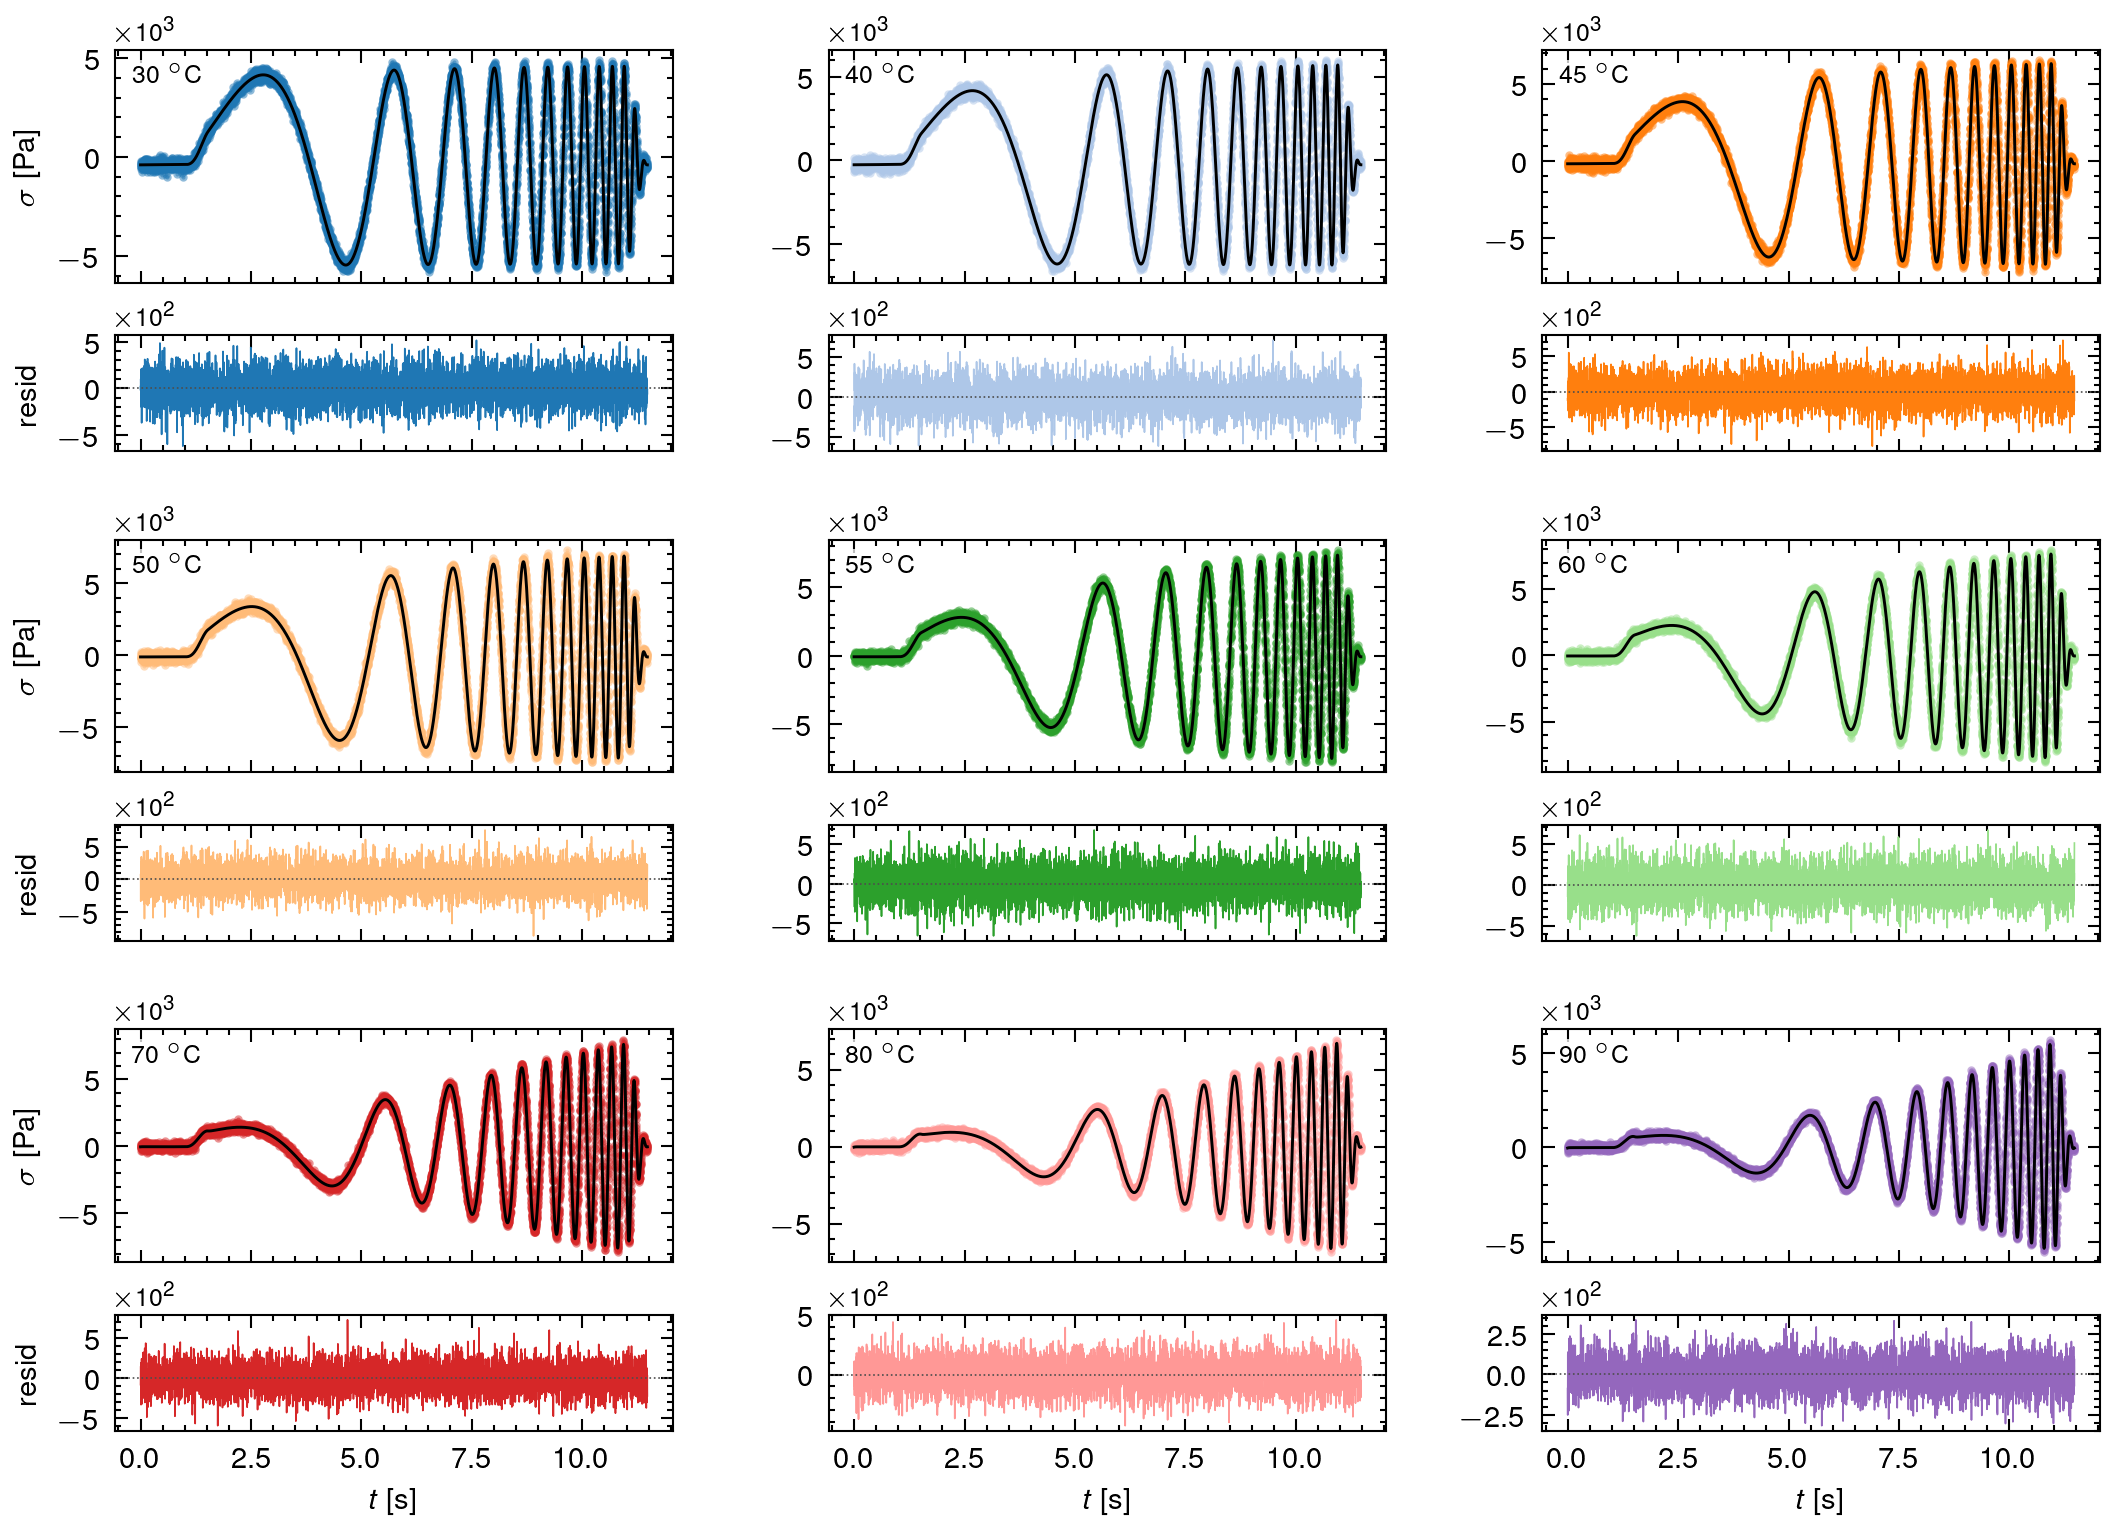

In [5]:
"""
plot_residuals_per_chirp.py
============================
Per-record (fit, residual) panels for every temperature in an
`export_master_curve()` bundle -- one fit+residual pair per chirp,
laid out on the SAME fixed-width (two-column, 7.0in) canvas as every
other figure in this notebook, so text reads at the identical size
once every figure is placed in the paper, regardless of how many
panels a given figure holds. No import of `paper_utils`, `rheogp`, or
`torch` -- copy this next to your exported data and run it.

Same visual language as this notebook's own master-curve figure: the
model's own prediction always plotted in black, measured data colored
by its own record's fixed (color, marker) identity from `record_style`
(discrete TAB20 cycle -- this notebook's established convention, kept
as-is rather than switching to a continuous colormap), each panel's
sci-notation y-offset kept independent (`use_sci_y`) since a residual
band and a raw stress axis can be orders of magnitude apart. No
figure/axes titles -- which temperature a panel belongs to is an
in-axes text label, not a title; a caption belongs in the paper, not
the image.

Layout note: constrained_layout is turned OFF for this specific figure
(overriding this notebook's usual default). With a grid-of-grids this
deep -- one nested fit+residual pair per record, tiled across a big
outer grid -- constrained_layout's automatic margin solver inflates
the gap BETWEEN records to several times the gap WITHIN a record's own
fit+residual pair, regardless of the hspace values actually asked for.
Doing the margins by hand via plain GridSpec fractions instead gives
direct, predictable control: tight within a record, modestly larger
between records.

Edit EXPORT_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
EXPORT_PATH = f"{DATA_DIR}/fmm_export"
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/fmm_residuals_per_chirp"
NCOLS = 3                      # 9 records -> a clean 3x3 grid


def load_export(path):
    from types import SimpleNamespace
    with open(f"{path}.json") as fh:
        meta = json.load(fh)
    data = np.load(f"{path}.npz")
    arrays = {k: data[k] for k in data.files}

    def record(i):
        pfx = f"rec{i}_"
        return {k[len(pfx):]: v for k, v in arrays.items() if k.startswith(pfx)}

    return SimpleNamespace(meta=meta, arrays=arrays, record=record,
                            n_records=meta["n_records"])


try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})

TAB10 = plt.cm.tab20.colors  # discrete colors, cycled per record -- same as
                             # this notebook's master-curve figure
MARKERS = ["o", "s", "^", "v", "D", "P", "X", "*", "h", "8"]  # cycled per record
COLOR_PRED = "black"  # model prediction -- fixed, not per-record, matches
                       # the master-curve figure's own convention


def record_style(i):
    """Fixed (color, marker) pair per record index -- same identity
    convention as the master-curve figure above."""
    return TAB10[i % len(TAB10)], MARKERS[i % len(MARKERS)]


def use_sci_y(ax, fontsize=6):
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(fontsize)


data = load_export(EXPORT_PATH)
T = np.asarray(data.arrays["temperatures"], float)
n_rec = data.n_records

nrows = int(np.ceil(n_rec / NCOLS))

# last populated row for each column -- since records fill row-major and
# the final row can be partial, a column's actual bottom panel is not
# always in row (nrows - 1)
last_row_for_col = {}
for i in range(n_rec):
    r, c = divmod(i, NCOLS)
    last_row_for_col[c] = max(last_row_for_col.get(c, -1), r)

# constrained_layout OFF just for this figure -- see module docstring.
plt.rcParams["figure.constrained_layout.use"] = False
fig = plt.figure(figsize=(7.0, 1.65 * nrows))
outer = gridspec.GridSpec(nrows, NCOLS, figure=fig, wspace=0.28, hspace=0.22,
                           left=0.05, right=0.995, top=0.98, bottom=0.05)

for i in range(n_rec):
    r, c = divmod(i, NCOLS)
    inner = gridspec.GridSpecFromSubplotSpec(
        2, 1, subplot_spec=outer[r, c], height_ratios=[2.0, 1.0], hspace=0.3)
    ax_fit = fig.add_subplot(inner[0])
    ax_res = fig.add_subplot(inner[1], sharex=ax_fit)

    rec = data.record(i)
    col, _mk = record_style(i)
    resid = rec["sigma"] - rec["pred"]

    ax_fit.plot(rec["t"], rec["sigma"], color=col, lw=0.0, marker="o", ms=1.0, alpha=0.5)
    ax_fit.plot(rec["t"], rec["pred"], color=COLOR_PRED, lw=0.7)
    ax_fit.text(0.03, 0.94, f"${T[i]:g}~^\\circ\\mathrm{{C}}$", transform=ax_fit.transAxes,
                fontsize=6, ha="left", va="top",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.0))
    ax_fit.tick_params(labelbottom=False)
    use_sci_y(ax_fit)
    if c == 0:
        ax_fit.set_ylabel(r"$\sigma$ [Pa]")

    ax_res.plot(rec["t"], resid, color=col, lw=0.4)
    ax_res.axhline(0, color="0.3", lw=0.4, ls=":")
    use_sci_y(ax_res)
    if c == 0:
        ax_res.set_ylabel("resid")
    if r == last_row_for_col[c]:
        ax_res.set_xlabel(r"$t$ [s]")
    else:
        ax_res.tick_params(labelbottom=False)

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display
    display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)


FractionalMaxwell: ran 8060 epochs
wrote fmm_figures/fmm_convergence.pdf and fmm_figures/fmm_convergence.png


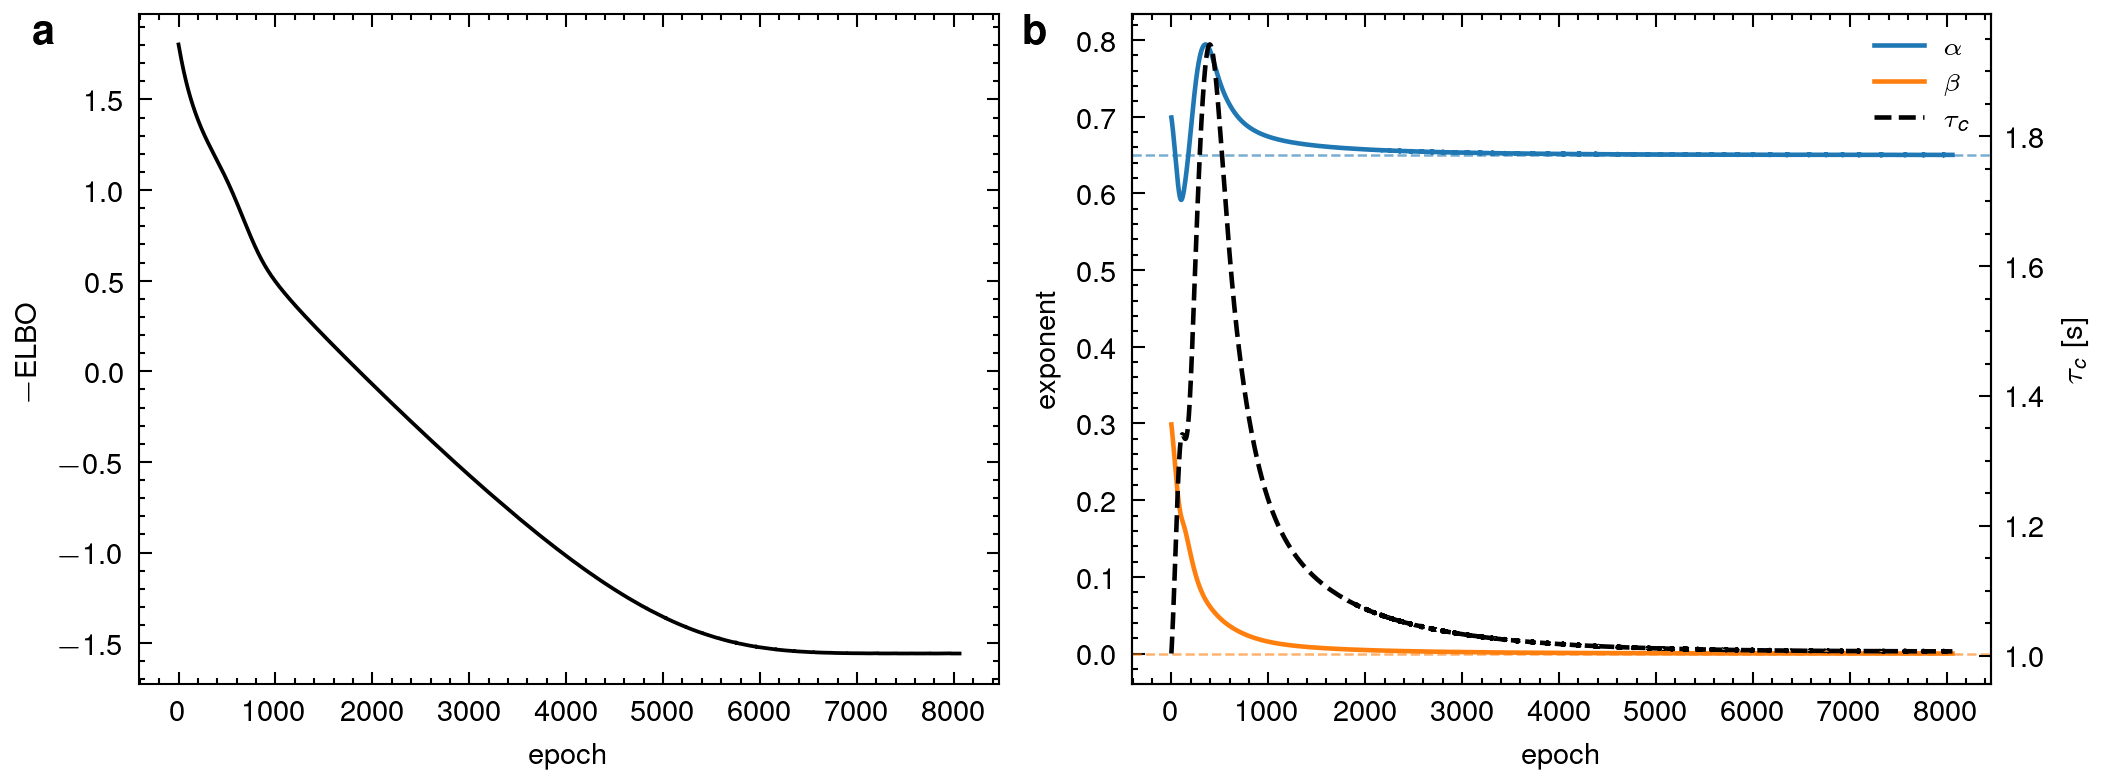

In [6]:
"""
plot_convergence.py
====================
Training-convergence figure from an `export_master_curve()` bundle's
`hist_loss` / `hist_param_*` arrays -- the same quantities
`SPGP.plot_convergence()` reads from `history_`, replotted at this
notebook's own fixed two-column width (7.0in) and font sizes so it
sits next to every other figure without a font-size mismatch. No
import os
import of `paper_utils`, `rheogp`, or `torch`.

Left: training loss (-ELBO, lower is better) vs. epoch. Right: every
shared shape parameter vs. epoch, alpha/beta on the primary axis
(dimensionless exponents), tau_c on its own secondary axis (its own
units/scale) -- same layout convention as `rheogp.plots.plot_convergence`.

Edit EXPORT_PATH / OUT_NAME and run.
"""
import json
import numpy as np
import matplotlib.pyplot as plt

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
EXPORT_PATH = f"{DATA_DIR}/fmm_export"
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/fmm_convergence"

with open(f"{EXPORT_PATH}.json") as fh:
    meta = json.load(fh)
data = np.load(f"{EXPORT_PATH}.npz")

try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})


def add_panel_letter(ax, text, xoff=-20, yoff=0, fontsize=10):
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


loss = data["hist_loss"]
param_names = [k[len("hist_param_"):] for k in data.files if k.startswith("hist_param_")]
params = {k: data[f"hist_param_{k}"] for k in param_names}
n_epochs_ran = len(loss)

PARAM_COLORS = {"alpha": "tab:blue", "beta": "tab:orange"}
PARAM_LABELS = {"alpha": r"$\alpha$", "beta": r"$\beta$"}
TAU_COLOR = "black"

fig, (ax_loss, ax_par) = plt.subplots(1, 2, figsize=(7.0, 2.6))

ax_loss.plot(loss, lw=0.9, color="k")
ax_loss.set_xlabel("epoch")
ax_loss.set_ylabel(r"$-\mathrm{ELBO}$")
add_panel_letter(ax_loss, r"$\mathbf{a}$")

ax_par_r = ax_par.twinx()
lines, labels = [], []
for name, vals in params.items():
    if name == "tau_c":
        continue
    c = PARAM_COLORS.get(name, "0.3")
    h, = ax_par.plot(vals, lw=1.1, color=c)
    ax_par.axhline(vals[-1], color=c, lw=0.6, ls="--", alpha=0.6)
    lines.append(h); labels.append(PARAM_LABELS.get(name, f"${name}$"))
if "tau_c" in params:
    h_tau, = ax_par_r.plot(params["tau_c"], lw=1.1, ls="--", color=TAU_COLOR)
    ax_par_r.set_ylabel(r"$\tau_c$ [s]", color=TAU_COLOR, fontsize=7)
    ax_par_r.tick_params(axis="y", colors=TAU_COLOR, labelsize=7)
    lines.append(h_tau); labels.append(r"$\tau_c$")

ax_par.set_xlabel("epoch")
ax_par.set_ylabel("exponent")
ax_par.legend(lines, labels, frameon=False, loc="best", fontsize=6)
add_panel_letter(ax_par, r"$\mathbf{b}$")

n_budget = meta.get("n_epochs_budget", None)
tag = f"{meta['model_name']}: ran {n_epochs_ran} epochs"
if n_budget:
    tag += f"/{n_budget}"
print(tag)

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display
    display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)


FractionalMaxwell
   T [C]    tau_int          N      N_eff
      30        1.0       5736     5696.2
      40        1.3       5736     4582.4
      45        1.0       5736     5582.2
      50        1.0       5736     5736.0
      55        1.0       5736     5736.0
      60        1.0       5736     5696.2
      70        1.0       5736     5736.0
      80        1.0       5736     5736.0
      90        1.0       5736     5736.0
pooled: N=51624, N_eff=50237.0, mean tau_int=1.0
wrote fmm_figures/fmm_residual_autocorr.pdf and fmm_figures/fmm_residual_autocorr.png


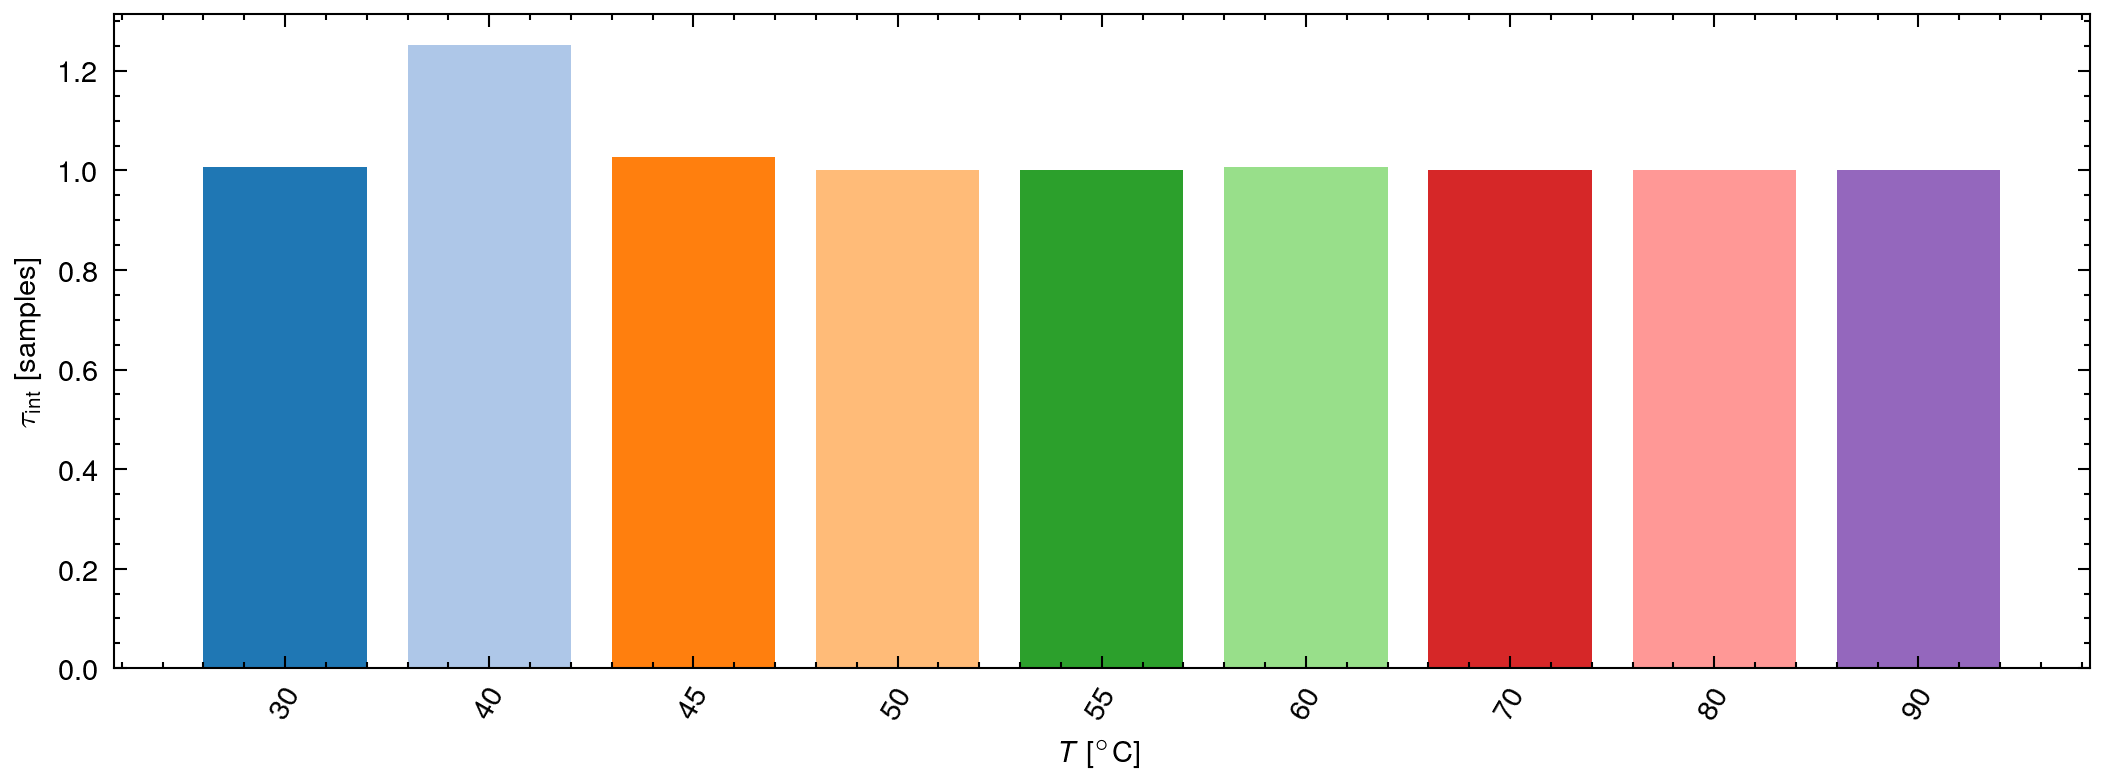

In [7]:
"""
plot_residual_autocorrelation.py
=================================
Residual integrated-autocorrelation-time (tau_int) per record, from an
`export_master_curve()` bundle, at this notebook's fixed two-column
width (7.0in) / font sizes. No import of `paper_utils`, `rheogp`, or
`torch`: `integrated_autocorr_time` below is a pure-numpy
re-implementation of `rheogp.utils.integrated_autocorr_time` (FFT
autocorrelation + Geyer's initial-positive-sequence rule, Sokal 1989 --
the same estimator emcee/ArviZ use for MCMC chains), applied to each
record's own residual (sigma - pred) since autocorrelation only means
something WITHIN one chirp, never across the concatenated multi-record
vector.

Bars colored by this notebook's own fixed per-record (color, marker)
identity (`record_style`, discrete TAB20 cycle), same convention as
the master-curve figure above -- kept as-is rather than switching to a
continuous colormap.

Edit EXPORT_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
EXPORT_PATH = f"{DATA_DIR}/fmm_export"
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/fmm_residual_autocorr"


def _acf(x, nlags=None):
    """Normalised autocorrelation function via FFT (zero-padded to
    avoid circular wrap-around), rho[0] == 1."""
    x = np.asarray(x, float)
    x = x - x.mean()
    n = x.size
    if n < 2:
        return np.array([1.0])
    if nlags is None:
        nlags = min(n - 1, 5000)
    nfft = 1 << int(np.ceil(np.log2(2 * n)))
    f = np.fft.rfft(x, nfft)
    r = np.fft.irfft(f * np.conjugate(f), nfft)[:nlags + 1].real
    return r / r[0] if r[0] > 0 else np.zeros_like(r)


def integrated_autocorr_time(x, nlags=5000):
    """tau_int = 1 + 2*sum_k rho_k via Geyer's initial-positive-sequence
    rule: accumulate consecutive lag PAIRS while their sum stays
    positive. Returns tau_int >= 1.0."""
    x = np.asarray(x, float)
    n = x.size
    if n < 4:
        return 1.0
    rho = _acf(x, nlags=min(nlags, n - 1))
    s, k = 0.0, 1
    while k + 1 < rho.size:
        pair = rho[k] + rho[k + 1]
        if pair <= 0:
            break
        s += pair
        k += 2
    return float(max(1.0 + 2.0 * s, 1.0))


with open(f"{EXPORT_PATH}.json") as fh:
    meta = json.load(fh)
data = np.load(f"{EXPORT_PATH}.npz")
T = np.asarray(data["temperatures"], float)
n_rec = int(meta["n_records"])

try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})

TAB10 = plt.cm.tab20.colors
MARKERS = ["o", "s", "^", "v", "D", "P", "X", "*", "h", "8"]


def record_style(i):
    return TAB10[i % len(TAB10)], MARKERS[i % len(MARKERS)]


tau_int = np.empty(n_rec)
n_raw = np.empty(n_rec, dtype=int)
for i in range(n_rec):
    resid = data[f"rec{i}_sigma"] - data[f"rec{i}_pred"]
    tau_int[i] = integrated_autocorr_time(resid)
    n_raw[i] = resid.size

n_eff = n_raw / tau_int
print(f"{meta['model_name']}")
print(f"{'T [C]':>8} {'tau_int':>10} {'N':>10} {'N_eff':>10}")
for i in range(n_rec):
    print(f"{T[i]:>8g} {tau_int[i]:>10.1f} {n_raw[i]:>10d} {n_eff[i]:>10.1f}")
print(f"pooled: N={n_raw.sum()}, N_eff={n_eff.sum():.1f}, mean tau_int={tau_int.mean():.1f}")

fig, ax = plt.subplots(figsize=(7.0, 2.6))

bar_colors = [record_style(i)[0] for i in range(n_rec)]
ax.bar(range(n_rec), tau_int, color=bar_colors)
ax.set_xticks(range(n_rec))
ax.set_xticklabels([f"{t:g}" for t in T], rotation=60)
ax.set_xlabel(r"$T~[^\circ\mathrm{C}]$")
ax.set_ylabel(r"$\tau_{\mathrm{int}}$ [samples]")

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display
    display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)


single 34,916-sample chirp (2.5 decades) vs. multi-chirp master curve (5.3 decades)
wrote fmm_figures/fmm_broadband_demo.pdf and fmm_figures/fmm_broadband_demo.png


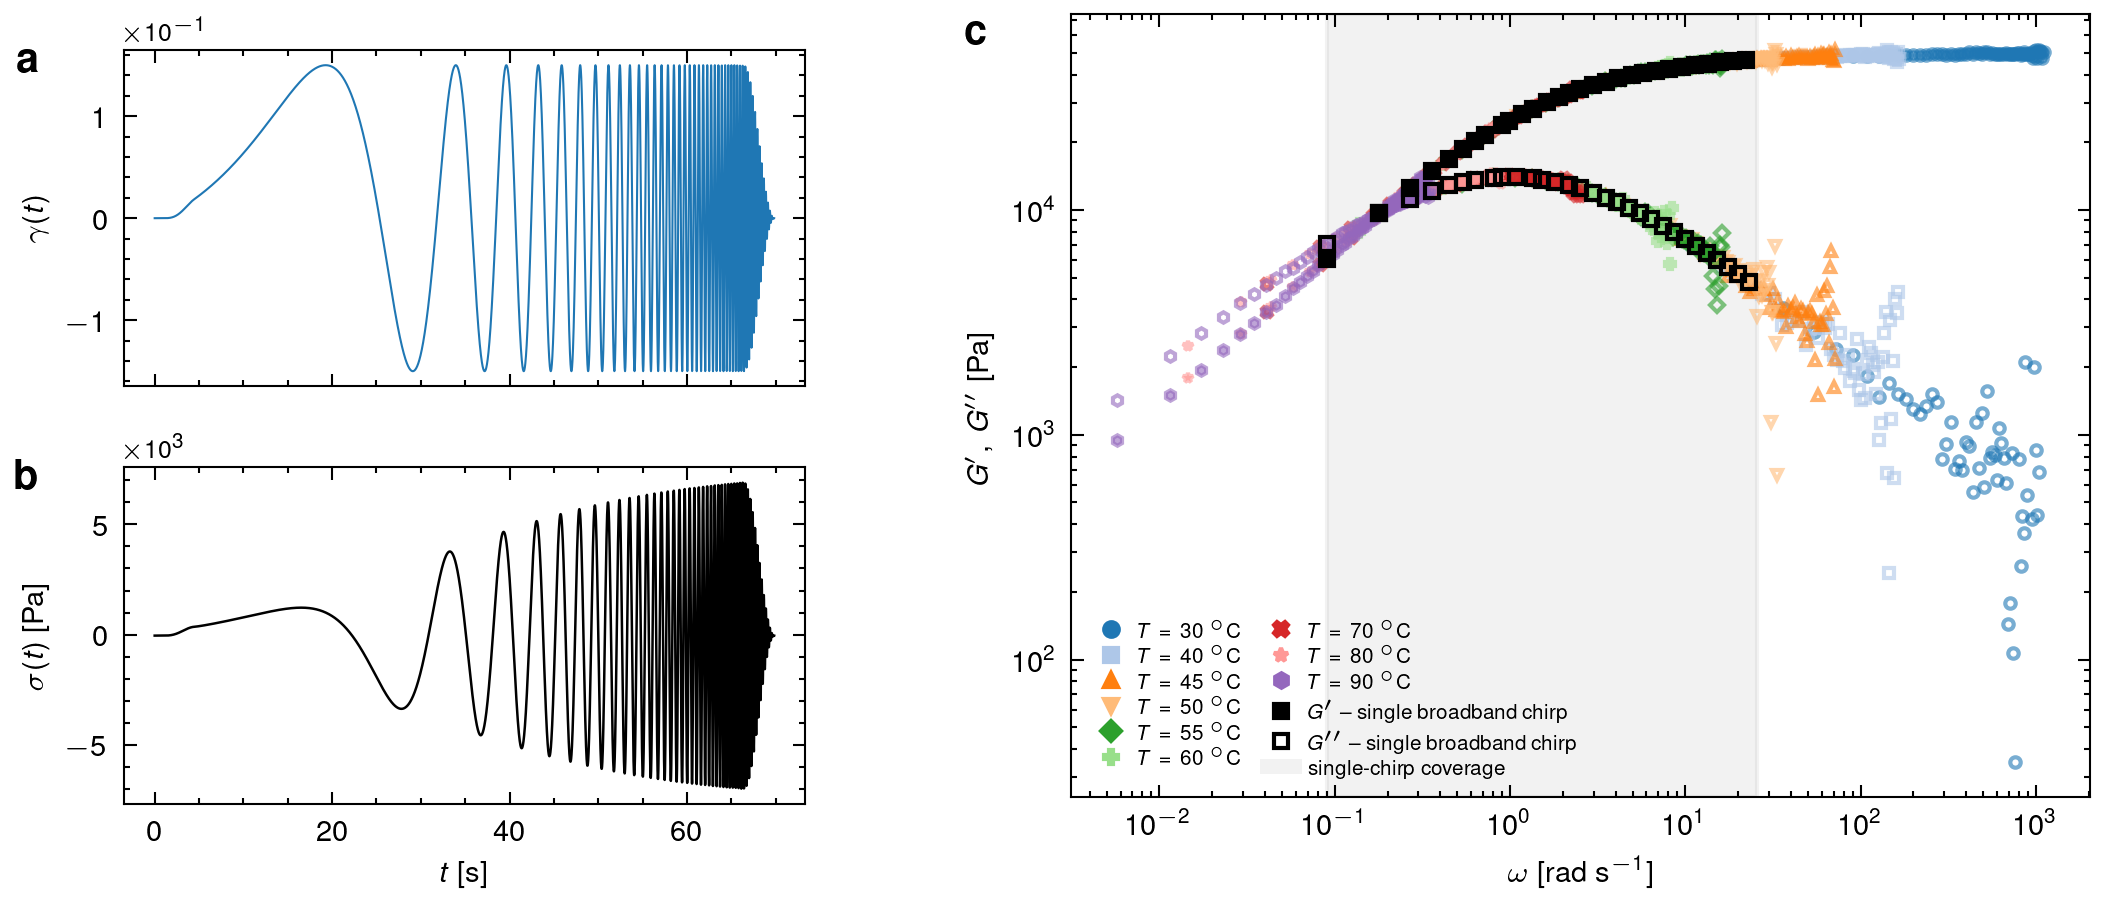

In [8]:
"""
plot_broadband_chirp_demo.py
=============================
"One huge chirp instead of TTS" self-consistency check, from the
`fmm_broadband_demo.npz`/.json bundle written alongside the regular
`export_master_curve()` export (see 01_synthetic_fmm_tts.ipynb for the
joint fit, and `run_broadband_demo_fmm.py` for how this bundle is
built). No import of `paper_utils`, `rheogp`, or `torch` -- pure
numpy/json, same standalone-script convention as this notebook's other
figures, at the SAME fixed two-column width (7.0in) and font sizes.

Layout mirrors the master-curve figure's own column split: LEFT column
stacks the synthetic broadband chirp's input strain and the stress
response the WINNING model's own physics predicts for it (a forward
simulation through the analytic Gstar transfer function -- not a
regression fit to anything, so there is nothing else to overlay on
it) on a shared time axis; RIGHT panel overlays that single-chirp
G'/G'' reconstruction on the REAL multi-chirp data, shaded over the
frequency range the single chirp can actually reach.

The right panel deliberately matches the master-curve figure's own
spectrum-panel convention instead of a smooth analytic curve: the
multi-chirp side is the ACTUAL per-record FFT points (from the main
`export_master_curve()` bundle, `EXPORT_PATH`), colored by this
notebook's own fixed per-record (color, marker) identity
(`record_style`, discrete TAB20 cycle -- kept as-is rather than
switching to a continuous colormap); the single-broadband-chirp side is
that record's own G'/G'' reconstruction (from the fresh single-record
regression in `run_broadband_demo_fmm.py` -- the self-consistency
check itself: can one chirp's own regression recover the same physics
the joint fit found?) drawn as scattered squares, same filled/open =
G'/G'' convention, in one fixed color so it reads as a single series
against the per-temperature real data underneath it.

Edit EXPORT_PATH / DEMO_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
EXPORT_PATH = f"{DATA_DIR}/fmm_export"           # the multi-chirp joint-fit export (real data)
DEMO_PATH = f"{DATA_DIR}/fmm_broadband_demo"     # the single-chirp self-consistency bundle
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/fmm_broadband_demo"
DOWNSAMPLE = 4            # stride for the time-domain panels (display only)

with open(f"{DEMO_PATH}.json") as fh:
    meta = json.load(fh)
data = np.load(f"{DEMO_PATH}.npz")
with open(f"{EXPORT_PATH}.json") as fh:
    export_meta = json.load(fh)
export = np.load(f"{EXPORT_PATH}.npz")
T = np.asarray(export["temperatures"], float)
n_rec = int(export_meta["n_records"])

try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})

TAB10 = plt.cm.tab20.colors
MARKERS = ["o", "s", "^", "v", "D", "P", "X", "*", "h", "8"]
COLOR_INPUT = "tab:blue"     # single fixed color -- one record, no per-T identity needed
COLOR_PRED = "black"         # model prediction -- fixed, matches every other figure
COLOR_DEMO = "black"         # single-broadband-chirp G'/G'' markers


def record_style(i):
    return TAB10[i % len(TAB10)], MARKERS[i % len(MARKERS)]


def add_panel_letter(ax, text, xoff=-20, yoff=0, fontsize=10):
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


def use_sci_y(ax, fontsize=6):
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(fontsize)


t = data["t_demo"][::DOWNSAMPLE]
strain = data["strain_demo"][::DOWNSAMPLE]
stress = data["stress_demo"][::DOWNSAMPLE]

fig = plt.figure(figsize=(7.0, 3.0))
outer = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.0, 1.25], wspace=0.28)
gs_left = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[0], hspace=0.1)
ax_strain = fig.add_subplot(gs_left[0])
ax_stress = fig.add_subplot(gs_left[1], sharex=ax_strain)
ax_spec = fig.add_subplot(outer[1])

# -- left, top: input chirp --------------------------------------------
ax_strain.plot(t, strain, color=COLOR_INPUT, lw=0.5)
ax_strain.set_ylabel(r"$\gamma(t)$")
ax_strain.tick_params(labelbottom=False)
use_sci_y(ax_strain)
add_panel_letter(ax_strain, r"$\mathbf{a}$", yoff=2)

# -- left, bottom: stress response THE MODEL PREDICTS for that input --
# a direct forward simulation through the fitted physics' analytic
# Gstar (plus the same small observation-noise level used elsewhere in
# this notebook) -- a single deterministic curve, not a fit to
# anything, so there is no separate "prediction" line to overlay on it.
ax_stress.plot(t, stress, color=COLOR_PRED, lw=0.6)
ax_stress.set_ylabel(r"$\sigma(t)$ [Pa]")
ax_stress.set_xlabel(r"$t$ [s]")
use_sci_y(ax_stress)
add_panel_letter(ax_stress, r"$\mathbf{b}$", yoff=2)

# -- right: real multi-chirp data (scattered, per-record color+marker)
# vs. the single broadband chirp's own G'/G'' (scattered squares, one
# fixed color) -- filled marker = G', open marker = G'' in both series,
# same convention as the master-curve figure's own spectrum panels.
for i in range(n_rec):
    c, mk = record_style(i)
    om_r = export[f"rec{i}_fft_omega_reduced"]
    ax_spec.loglog(om_r, export[f"rec{i}_fft_Gp"], marker=mk, ms=2.5,
                   ls="none", mfc=c, mec=c, alpha=0.6)
    ax_spec.loglog(om_r, export[f"rec{i}_fft_Gdp"], marker=mk, ms=2.5,
                   ls="none", mfc="none", mec=c, alpha=0.6)

omega_d, Gp_d, Gdp_d = data["omega_demo"], data["Gp_demo"], data["Gdp_demo"]
h_gp, = ax_spec.loglog(omega_d, Gp_d, marker="s", ms=3.2, ls="none",
                        mfc=COLOR_DEMO, markevery=0.01, mec=COLOR_DEMO)
h_gdp, = ax_spec.loglog(omega_d, Gdp_d, marker="s", ms=3.2, ls="none",
                         mfc="none", markevery=0.01, mec=COLOR_DEMO)
ax_spec.axvspan(meta["demo_lo"], meta["demo_hi"], color="0.5", alpha=0.10)

ax_spec.set_xlabel(r"$\omega~[\mathrm{rad~s}^{-1}]$")
ax_spec.set_ylabel(r"$G',\,G''$ [Pa]")

temp_handles = [plt.Line2D([], [], marker=record_style(i)[1], ls="none",
                           mfc=record_style(i)[0], mec=record_style(i)[0], ms=3.5,
                           label=f"$T={T[i]:g}~^\\circ\\mathrm{{C}}$")
               for i in range(n_rec)]
demo_handles = [
    h_gp, h_gdp,
    plt.matplotlib.patches.Patch(facecolor="0.5", alpha=0.10),
]
demo_labels = ["$G'$ -- single broadband chirp", "$G''$ -- single broadband chirp",
               "single-chirp coverage"]
ax_spec.legend(handles=temp_handles + demo_handles,
               labels=[h.get_label() for h in temp_handles] + demo_labels,
               frameon=False, fontsize=5, loc="best", ncol=2,
               columnspacing=0.8, handletextpad=0.3, labelspacing=0.3)
add_panel_letter(ax_spec, r"$\mathbf{c}$")

print(f"single {meta['N_DEMO']:,.0f}-sample chirp ({meta['n_decades_demo']:.1f} decades) "
      f"vs. multi-chirp master curve ({meta['n_decades_full']:.1f} decades)")

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display
    display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)


joint fit family : FMM
noise levels     : 3%, 8%, 15%, 25%
  noise      alpha       beta      tau_c      Gc [Pa]        C1    C2 [K]
-------------------------------------------------------------------------
    3%     0.6500     0.0000     1.0045    4.997e+04     8.421    130.24
    8%     0.6501     0.0003     1.0027    4.994e+04     8.330    128.69
   15%     0.6514     0.0003     1.0025    4.991e+04     8.131    124.90
   25%     0.6510     0.0018     1.0197    4.967e+04     8.248    126.93
 truth     0.6500     0.0000     1.0000        5e+04     8.400    130.00
wrote fmm_figures/fmm_noise_parameter_recovery.pdf and fmm_figures/fmm_noise_parameter_recovery.png


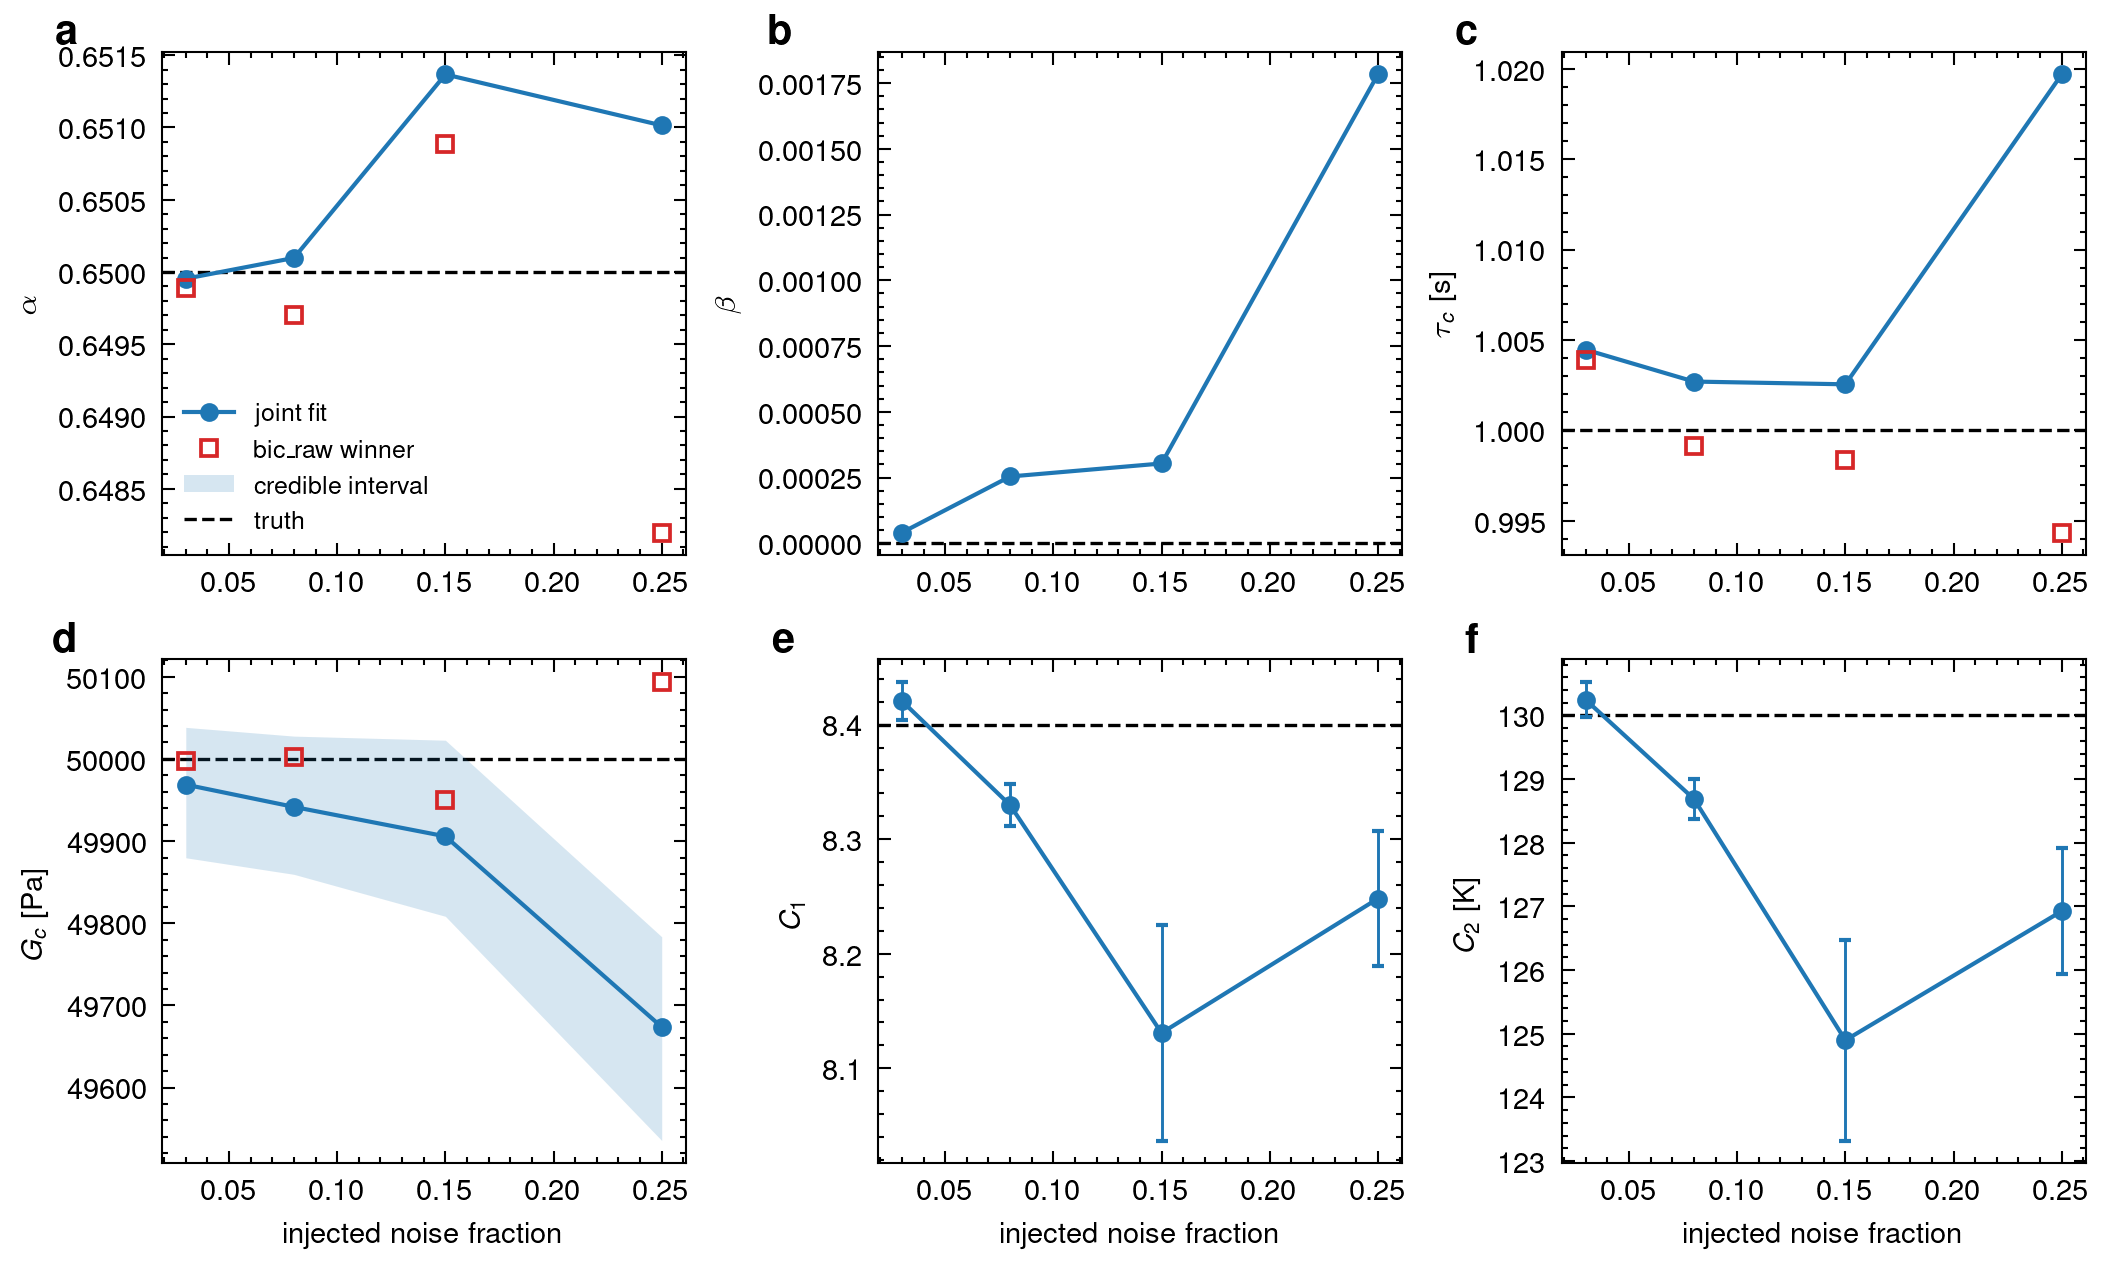

In [9]:
"""
plot_noise_parameter_recovery.py
=================================
Parameter recovery vs. injected measurement noise, from the
`export_noise_sweep()` bundle written by Sec. 9 of
`01_synthetic_fmm_tts.ipynb` (`fmm_noise_sweep.json`). Every shared
shape parameter and prefactor the joint fit recovers, plus the WLF
constants regressed from its own shift factors, each against the
ground truth the synthetic data was generated from. Same fixed
two-column width (7.0in) and font sizes as every other figure in this
notebook. No import of `paper_utils`, `rheogp`, or `torch` -- pure
json + numpy, so this runs next to the exported data on any machine.

The series plotted are the joint fit of ONE fixed model family (the
bundle's `fit_model`, i.e. whatever `FITKW["model"]` was), at every
noise level -- so the columns stay comparable across rows even where
the SELECTED model changes with noise. Set `SHOW_WINNER = True` to
overlay, as open markers, the same parameter as recovered by whichever
candidate won on BIC at that noise level (nothing is drawn at a noise
level whose winning family has no such parameter -- Maxwell has no
alpha/beta, FMG no beta, FML no alpha).

Edit EXPORT_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
EXPORT_PATH = f"{DATA_DIR}/fmm_noise_sweep"
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/fmm_noise_parameter_recovery"
SHOW_WINNER = True
WINNER_CRITERION = "bic_raw"      # "aic" / "bic_raw" / "bic_eff_pen" / "bic_eff_full"

with open(f"{EXPORT_PATH}.json") as fh:
    bundle = json.load(fh)

rows = sorted(bundle["rows"], key=lambda r: r["noise_frac"])
truth = bundle.get("truth", {})
display = bundle.get("display_names", {})
noise = np.array([r["noise_frac"] for r in rows], float)


def dig(d, keys):
    for k in keys:
        if d is None:
            return None
        d = d.get(k)
    return d


def series(*keys):
    """One nested scalar per noise level, NaN where a fit has no such
    parameter (so a partially-defined series still plots)."""
    out = []
    for r in rows:
        v = dig(r, keys)
        out.append(np.nan if v is None else float(v))
    return np.asarray(out, float)


def winner_series(*keys):
    out = []
    for r in rows:
        w = r["winners"][WINNER_CRITERION]
        v = dig(r["candidates"].get(w), keys)
        out.append(np.nan if v is None else float(v))
    return np.asarray(out, float)


try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})


# yoff lifts the letter clear of the topmost y tick label, which in
# this figure's narrow panels sits at the same height as the letter
def add_panel_letter(ax, text, xoff=-20, yoff=9, fontsize=10):
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


FIT_COLOR = "tab:blue"
WIN_COLOR = "tab:red"
TRUTH_KW = dict(color="k", ls="--", lw=0.8, zorder=1)
FIT_KW = dict(marker="o", ms=3.5, lw=1.0, color=FIT_COLOR, zorder=3)
WIN_KW = dict(marker="s", ms=4.0, lw=0.0, mfc="none", mew=0.9,
              mec=WIN_COLOR, zorder=4)

fig, axs = plt.subplots(2, 3, figsize=(7.0, 4.2))
(axA, axB, axC), (axD, axE, axF) = axs

# ---- (a,b,c) shared shape parameters --------------------------------
SHAPE = [
    (axA, r"$\mathbf{a}$", "alpha", r"$\alpha$", truth.get("alpha")),
    (axB, r"$\mathbf{b}$", "beta", r"$\beta$", truth.get("beta")),
    (axC, r"$\mathbf{c}$", "tau_c", r"$\tau_c$ [s]", truth.get("tau_ref")),
]
for ax, letter, key, ylabel, tval in SHAPE:
    y = series("fit", "params", key)
    ax.plot(noise, y, label="joint fit", **FIT_KW)
    if SHOW_WINNER:
        yw = winner_series("params", key)
        if np.any(np.isfinite(yw)):
            ax.plot(noise, yw, label=f"{WINNER_CRITERION} winner", **WIN_KW)
    if tval is not None:
        ax.axhline(float(tval), label="truth", **TRUTH_KW)
    ax.set_ylabel(ylabel)
    add_panel_letter(ax, letter)

# ---- (d) prefactor, with its posterior credible band -----------------
Gc = series("fit", "prefactors", "Gc", "mean")
Gc_lo = series("fit", "prefactors", "Gc", "lower")
Gc_hi = series("fit", "prefactors", "Gc", "upper")
if np.all(np.isfinite(Gc_lo)) and np.all(np.isfinite(Gc_hi)):
    axD.fill_between(noise, Gc_lo, Gc_hi, color=FIT_COLOR, alpha=0.18, lw=0,
                     zorder=2, label="credible interval")
axD.plot(noise, Gc, label="joint fit", **FIT_KW)
if SHOW_WINNER:
    Gw = winner_series("prefactors", "Gc", "mean")
    if np.any(np.isfinite(Gw)):
        axD.plot(noise, Gw, label=f"{WINNER_CRITERION} winner", **WIN_KW)
if truth.get("Gc") is not None:
    axD.axhline(float(truth["Gc"]), label="truth", **TRUTH_KW)
axD.set_ylabel(r"$G_c$ [Pa]")
add_panel_letter(axD, r"$\mathbf{d}$")

# ---- (e,f) WLF constants, from each fit's own shift factors ----------
WLF = [
    (axE, r"$\mathbf{e}$", "C1", r"$C_1$", truth.get("C1")),
    (axF, r"$\mathbf{f}$", "C2", r"$C_2$ [K]", truth.get("C2")),
]
for ax, letter, key, ylabel, tval in WLF:
    y = series("fit", "wlf", key)
    yerr = series("fit", "wlf", f"{key}_std")
    ax.errorbar(noise, y, yerr=np.where(np.isfinite(yerr), yerr, 0.0),
                capsize=1.5, elinewidth=0.7, label="joint fit", **FIT_KW)
    if tval is not None:
        ax.axhline(float(tval), label="truth", **TRUTH_KW)
    ax.set_ylabel(ylabel)
    add_panel_letter(ax, letter)

for ax in (axD, axE, axF):
    ax.set_xlabel(r"injected noise fraction")

# One legend for the whole figure, built from proxies rather than from
# whichever panel happens to carry every artist: the winner overlay only
# exists on panels whose winning family HAS that parameter, and the
# credible band only on (d), so no single panel's own handles are
# complete.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

handles = [Line2D([], [], **{k: v for k, v in FIT_KW.items() if k != "zorder"},
                  label="joint fit")]
if SHOW_WINNER:
    handles.append(Line2D([], [], **{k: v for k, v in WIN_KW.items() if k != "zorder"},
                          label=f"{WINNER_CRITERION} winner"))
handles += [Patch(facecolor=FIT_COLOR, alpha=0.18, label="credible interval"),
            Line2D([], [], **{k: v for k, v in TRUTH_KW.items() if k != "zorder"},
                   label="truth")]
axA.legend(handles=handles, frameon=False, loc="best")

fit_model = bundle.get("fit_model", "?")
print(f"joint fit family : {display.get(fit_model, fit_model)}")
print(f"noise levels     : {', '.join(f'{n:.0%}' for n in noise)}")
hdr = (f"{'noise':>7} {'alpha':>10} {'beta':>10} {'tau_c':>10} {'Gc [Pa]':>12} "
       f"{'C1':>9} {'C2 [K]':>9}")
print(hdr); print("-" * len(hdr))
for i, r in enumerate(rows):
    p, w = r["fit"]["params"], r["fit"]["wlf"]
    print(f"{noise[i]:>6.0%} {p.get('alpha', float('nan')):>10.4f} "
          f"{p.get('beta', float('nan')):>10.4f} "
          f"{p.get('tau_c', float('nan')):>10.4f} {Gc[i]:>12.4g} "
          f"{w['C1']:>9.3f} {w['C2']:>9.2f}")
print(f"{'truth':>6} {truth.get('alpha', float('nan')):>10.4f} "
      f"{truth.get('beta', float('nan')):>10.4f} "
      f"{truth.get('tau_ref', float('nan')):>10.4f} "
      f"{truth.get('Gc', float('nan')):>12.4g} "
      f"{truth.get('C1', float('nan')):>9.3f} "
      f"{truth.get('C2', float('nan')):>9.2f}")

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display as _display
    _display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)

BIC resolution floor = 2*N*patience_tol = 2*51624*0.0001 = 10.3 units
Any gap below this is where the optimisers stopped, not model evidence.

true generating model: FMG (FractionalMaxwellGel)
  noise          bic_raw      bic_eff_pen     bic_eff_full
----------------------------------------------------------
    3%             FMG*             FMG*             FMG*
    8%             FMG*             FMG*             FMG*
   15%             FMG*             FMG*             FMG*
   25%             FMG*             FMG*             FMG*
* = the true generating model

  noise    winner  runner-up    margin  resolved?   (BIC raw, floor 10.3)
    3%       FMG        FMM      7.01  NO -- tie
    8%       FMG        FMM      6.64  NO -- tie
   15%       FMG        FMM      8.13  NO -- tie
   25%       FMG        FMM     10.39        YES

  noise     model   epochs    elbo/point
    3%       FMG     9297     -2.035113
    3%       FMM     9355     -2.035151
    8%       FMG     6970     -1.0

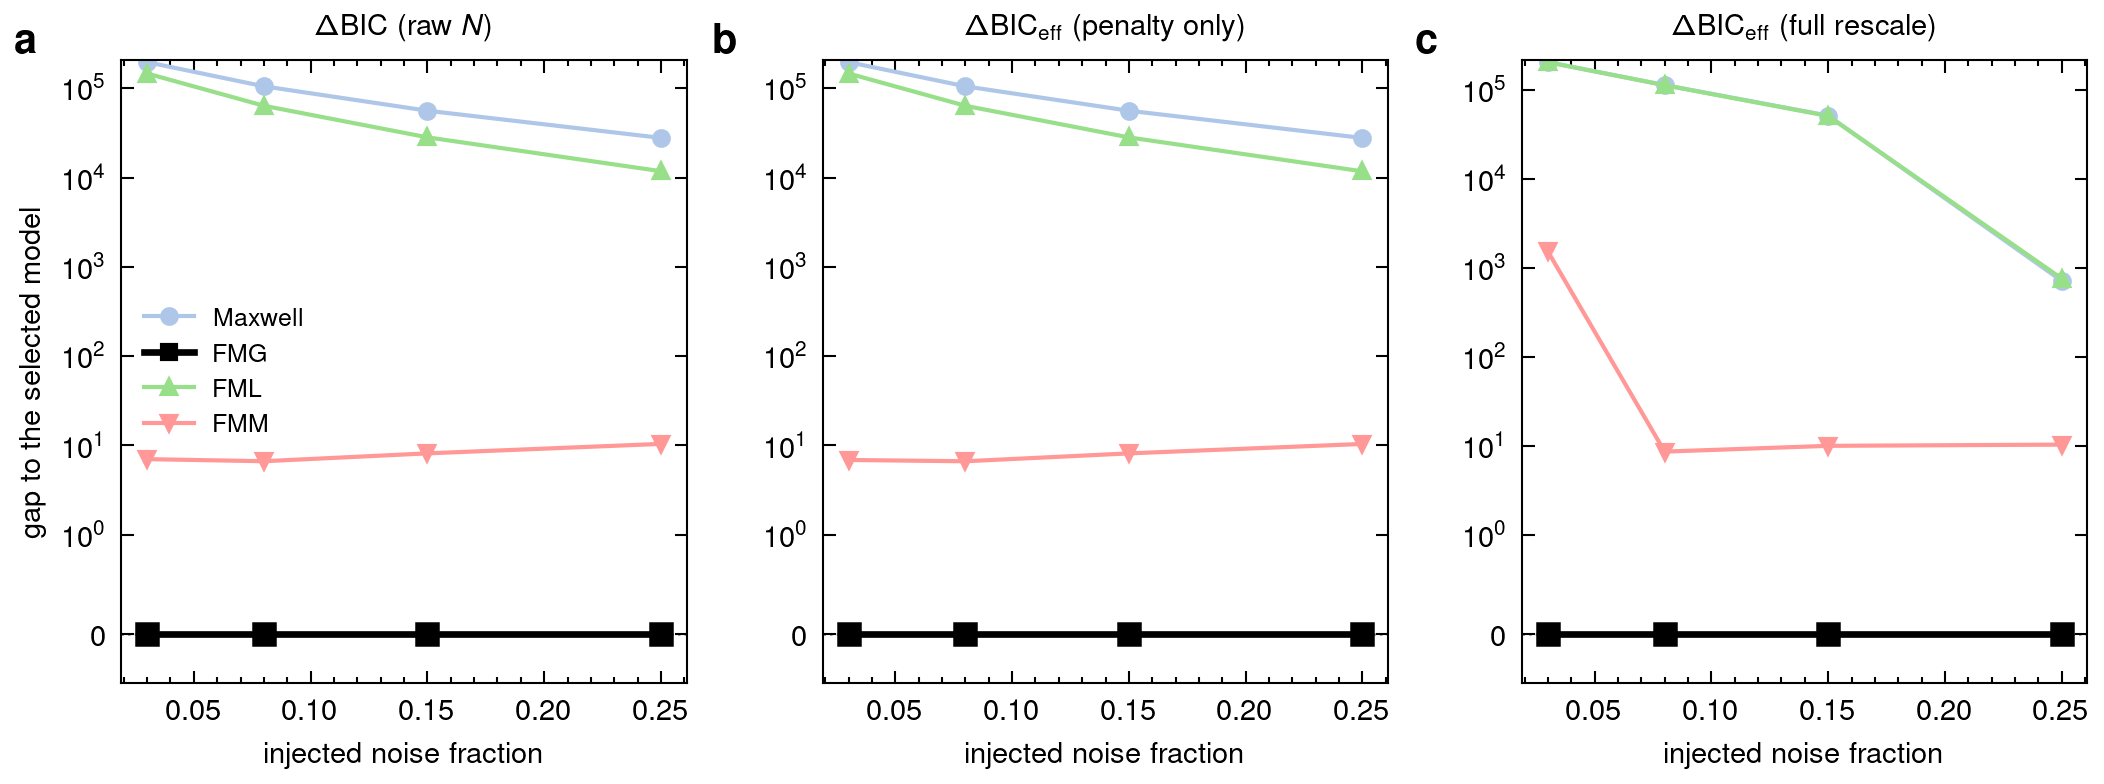

In [10]:
"""
plot_noise_model_selection.py
==============================
Which constitutive model the information criteria select, as a function
of injected measurement noise -- from the `export_noise_sweep()` bundle
written by Sec. 9 of `01_synthetic_fmm_tts.ipynb`
(`fmm_noise_sweep.json`). One panel per selection rule: the raw-N BIC
the library computes, and the two N_eff-corrected BIC conventions of
Sec. 5b (penalty-only, and likelihood rescaled too). Each panel plots
every candidate's gap to that panel's own winner, so the selected model
is the curve sitting on zero and the vertical axis reads directly as
"how much worse is this candidate". Same fixed two-column width (7.0in)
and font sizes as every other figure in this notebook. No import of
`paper_utils`, `rheogp`, or `torch`.

The true generating model is drawn in black with a heavier line; the
misspecified alternatives in the discrete TAB20 cycle this notebook
already uses elsewhere. A candidate curve that touches zero at some
noise level is a level where the criterion picked it.

Edit EXPORT_PATH / OUT_NAME / PANEL_CRITERIA and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
EXPORT_PATH = f"{DATA_DIR}/fmm_noise_sweep"
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/fmm_noise_model_selection"
PANEL_CRITERIA = ["bic_raw", "bic_eff_pen", "bic_eff_full"]
SYMLOG = True              # Delta spans orders of magnitude; keep zero visible
PATIENCE_TOL = 1e-4        # the fits' own `patience_tol` (SPGP default 1e-4).
                           # Early stopping accepts any epoch improving the
                           # per-point ELBO by less than this, so two candidates
                           # can differ by up to ~2*N*tol in -2logL purely from
                           # where their optimisers happened to stop. That sets
                           # a RESOLUTION FLOOR on BIC: gaps below it are
                           # optimiser slop, not evidence. Shaded in every
                           # panel below. Lower `patience_tol` (and raise
                           # `patience`) in the fit to push the floor down.

CRIT_LABEL = {"aic": r"$\Delta\mathrm{AIC}$",
              "bic_raw": r"$\Delta\mathrm{BIC}$ (raw $N$)",
              "bic_eff_pen": r"$\Delta\mathrm{BIC}_{\mathrm{eff}}$ (penalty only)",
              "bic_eff_full": r"$\Delta\mathrm{BIC}_{\mathrm{eff}}$ (full rescale)"}

with open(f"{EXPORT_PATH}.json") as fh:
    bundle = json.load(fh)

rows = sorted(bundle["rows"], key=lambda r: r["noise_frac"])
noise = np.array([r["noise_frac"] for r in rows], float)
candidates = bundle.get("candidates") or list(rows[0]["candidates"])
display = bundle.get("display_names", {})
true_model = bundle.get("true_model")


def disp(name):
    return display.get(name, name)


try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})


# yoff lifts the letter clear of the topmost y tick label, which in
# this figure's narrow panels sits at the same height as the letter
def add_panel_letter(ax, text, xoff=-20, yoff=9, fontsize=10):
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


TAB20 = plt.cm.tab20.colors
MARKERS = ["o", "s", "^", "v", "D", "P", "X", "*", "h", "8"]


def candidate_style(name):
    """Fixed (color, marker, lw) per candidate -- the true generating
    model always black and heavier, so it is findable in every panel."""
    i = candidates.index(name)
    if name == true_model:
        return "k", MARKERS[i % len(MARKERS)], 1.6
    return TAB20[(2 * i + 1) % len(TAB20)], MARKERS[i % len(MARKERS)], 1.0


# One number, from the fits' own stopping rule: how big a Delta has to be
# before it means anything at all.
n_data = int(rows[0]["candidates"][candidates[0]]["n_data"])
floor = 2.0 * n_data * PATIENCE_TOL
print(f"BIC resolution floor = 2*N*patience_tol = 2*{n_data}*{PATIENCE_TOL:g} "
      f"= {floor:.1f} units")
print("Any gap below this is where the optimisers stopped, not model evidence.\n")

fig, axs = plt.subplots(1, len(PANEL_CRITERIA),
                        figsize=(7.0, 2.6), sharex=True)
axs = np.atleast_1d(axs)

for j, (ax, crit) in enumerate(zip(axs, PANEL_CRITERIA)):
    for name in candidates:
        d = np.array([r["delta"][crit].get(name, np.nan) for r in rows], float)
        color, marker, lw = candidate_style(name)
        ax.plot(noise, d, marker=marker, ms=3.5, lw=lw, color=color,
                label=disp(name))
        # a filled marker wherever this candidate IS the winner
        won = np.array([r["winners"][crit] == name for r in rows], bool)
        if won.any():
            ax.plot(noise[won], d[won], marker=marker, ms=5.5, lw=0.0,
                    mfc=color, mec="k", mew=0.6, zorder=5)
    ax.axhline(0.0, color="0.5", lw=0.6, ls=":", zorder=1)
    # The resolution floor is reported in the printout below rather than
    # shaded on the axes -- the band competed with the data it qualified.
    if SYMLOG:
        # every Delta is >= 0 by construction (it is a gap to the best
        # candidate), so clip the axis just below zero rather than let
        # symlog spend half its range on decades nothing plots in
        ax.set_yscale("symlog", linthresh=1.0)
        ax.set_ylim(bottom=-0.5)
    ax.set_xlabel(r"injected noise fraction")
    ax.set_title(CRIT_LABEL.get(crit, crit), fontsize=7)
    add_panel_letter(ax, r"$\mathbf{" + "abcdefgh"[j] + r"}$")
axs[0].set_ylabel(r"gap to the selected model")
axs[0].legend(frameon=False, loc="best")

# ---- the selection table, printed alongside -------------------------
# AIC dropped from the figure and the tables. It is still computed and
# still in the exported bundle; it is simply not shown, since BIC on the
# raw N and the two N_eff conventions already span the selection
# question and AIC never disagreed with them here.
all_criteria = [c for c in PANEL_CRITERIA if c != "aic"]
print(f"true generating model: {disp(true_model)} ({true_model})")
hdr = f"{'noise':>7} " + " ".join(f"{c:>16}" for c in all_criteria)
print(hdr); print("-" * len(hdr))
for i, r in enumerate(rows):
    cells = " ".join(
        f"{disp(r['winners'][c]) + ('*' if r['winners'][c] == true_model else ''):>16}"
        for c in all_criteria)
    print(f"{noise[i]:>6.0%} {cells}")
print("* = the true generating model")

# Which selections actually clear the floor. A winner whose margin over the
# runner-up is inside the floor has not been distinguished from it, whatever
# the table above says.
print(f"\n{'noise':>7} {'winner':>9} {'runner-up':>10} {'margin':>9} "
      f"{'resolved?':>10}   (BIC raw, floor {floor:.1f})")
for i, r in enumerate(rows):
    rank = sorted(r["candidates"], key=lambda n: r["candidates"][n]["bic_raw"])
    margin = r["delta"]["bic_raw"][rank[1]]
    print(f"{noise[i]:>6.0%} {disp(rank[0]):>9} {disp(rank[1]):>10} "
          f"{margin:>9.2f} {('YES' if margin > floor else 'NO -- tie'):>10}")

# Early stopping is the mechanism behind the floor, so show where each
# candidate actually stopped: a winner that simply ran longer than its
# runner-up has not earned the gap.
print(f"\n{'noise':>7} {'model':>9} {'epochs':>8} {'elbo/point':>13}")
for i, r in enumerate(rows):
    rank = sorted(r["candidates"], key=lambda n: r["candidates"][n]["bic_raw"])[:2]
    for n in rank:
        c = r["candidates"][n]
        print(f"{noise[i]:>6.0%} {disp(n):>9} {c['n_epochs_ran']:>8d} "
              f"{c['elbo_per_point']:>13.6f}")

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display as _display
    _display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)

true generating model: FMG (FractionalMaxwellGel)
reference weight: the injected noise ('sd_realized')
proportional weight: (rho|y|)^2 + sigma_0^2, 50% of the budget proportional

noise 3%    sigma = 98.88 Pa    N = 51624    ln N = 10.852
model                       k  rmse [Pa]            chi2_v sig_hat              chi2_v sigma     chi2_v prop. to |y_i|  chi2_v GP predictive std    chi2_v GP std, matched
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Maxwell                    14      697.4                    0.9961                     49.74                     60.27                    0.9936                     49.73
FMG *                      15       98.9                    0.8965                         1                     1.242                    0.8137                    0.9999
FML                        15      429.2                    0.9911           

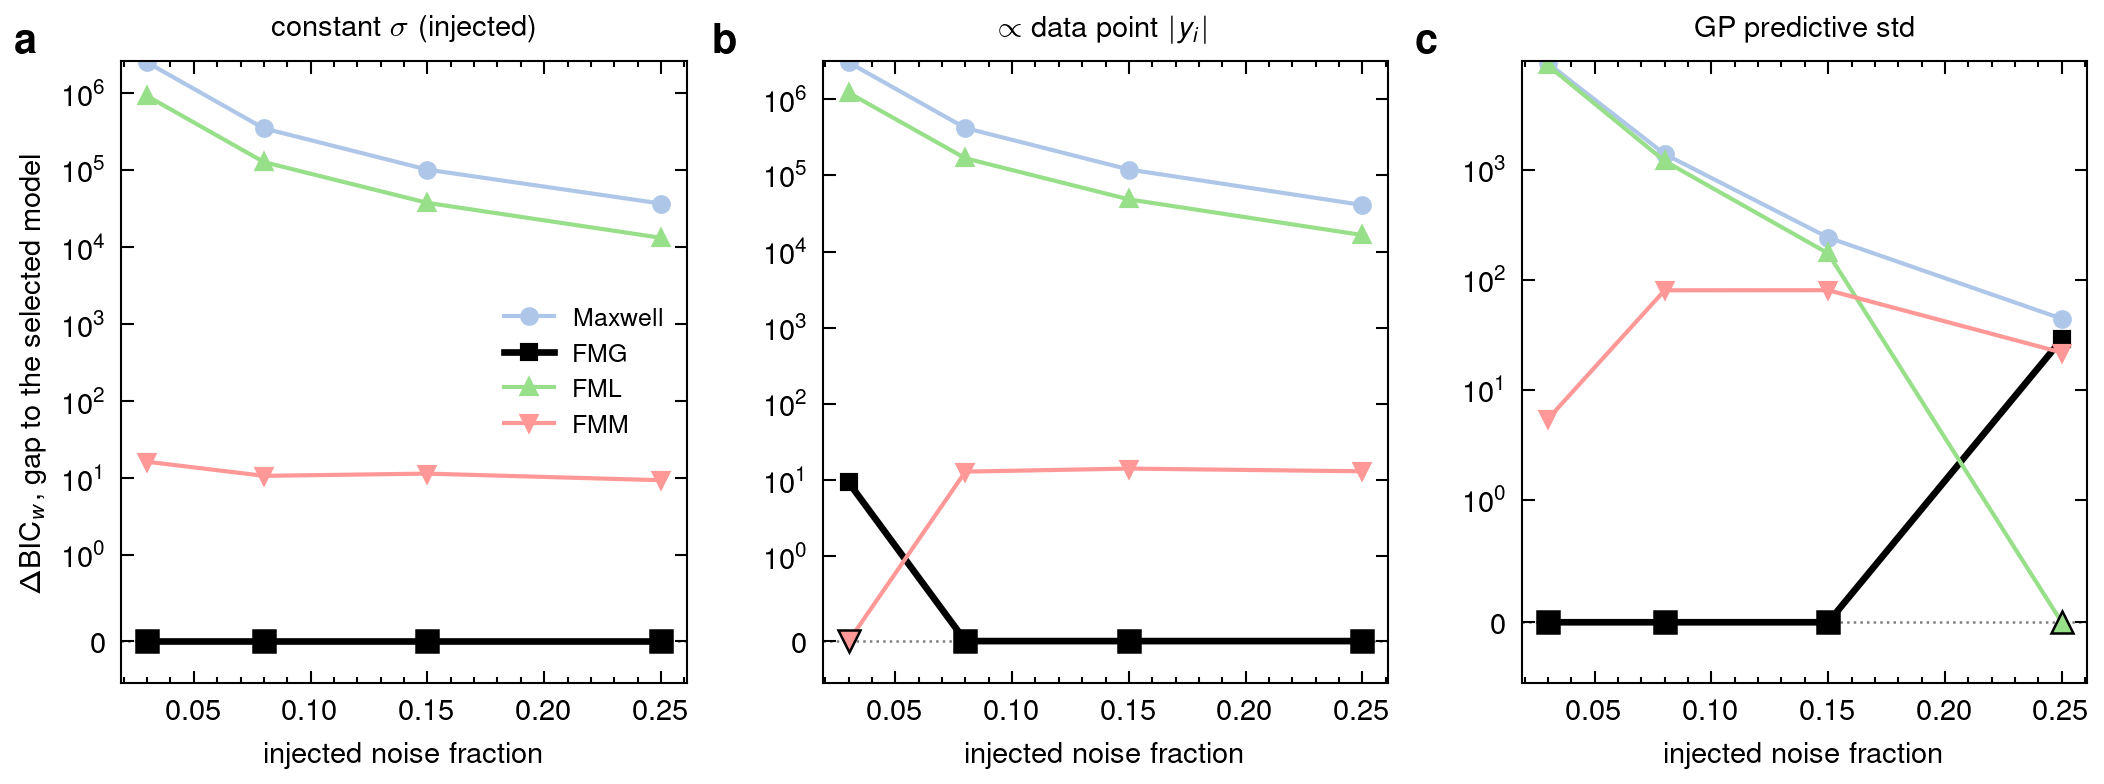

In [11]:
"""
plot_noise_weighted_rss.py
===========================
Model selection with the ELBO swapped out for a weighted residual sum
of squares, under three different choices of weight -- from the
`export_noise_sweep()` bundle every other cell here reads
(`fmm_noise_sweep.json`) plus the per-point arrays Sec. 9 writes
alongside it (`fmm_noise_sweep_pointwise.npz`). Nothing is refitted.
No import of `paper_utils`, `rheogp`, or `torch`.

WHY. The BIC the other cells plot is `2*U + k*ln(N)` with `U = -ELBO`.
That likelihood term is not the model's marginal likelihood: it is a
variational LOWER BOUND on it, and the gap between the two -- the KL to
the inducing-point posterior plus the posterior-variance trace -- is
not the same size for two candidates with different numbers of physics
parameters, so part of any BIC gap is approximation slack rather than
evidence. Replacing `2*U` with a weighted RSS removes that term and
leaves a criterion that sees only how far the predictions sit from the
data:

    BIC_w  =  sum_i r_i^2 / w_i^2  +  k * ln(N)

For Gaussian noise of KNOWN, CONSTANT variance this is not an
approximation of BIC -- it IS BIC, since
`-2 log L = sum r^2/sigma^2 + N ln(2 pi sigma^2)` and the second term
is identical for every candidate and cancels from every gap. Once the
weight varies per point that exactness goes away (the dropped term
becomes `sum_i ln w_i^2`, which is no longer common to all candidates
unless the weights are), so the per-point columns below are read as
diagnostics of how the weighting behaves, not as exact BICs.

THE FOUR WEIGHTS COMPARED
  sigma_hat (fitted)  each candidate's own fitted noise. DEGENERATE:
      the maximum-likelihood noise is sigma_hat^2 = RSS/N by
      definition, so sum r^2/sigma_hat^2 = N IDENTICALLY, for every
      candidate, however badly it fits. All the information moves into
      the `N ln sigma_hat^2` term the substitution discards. Reported
      in the printout as the control, and it is flat at one.
  sigma injected      the noise the generator actually added. The
      reference column: available only because the data are synthetic.
  |y_i| (proportional) the measured stress at that point, in the
      only form that survives oscillatory data -- see below.
  GP predictive std   sqrt(Var[f_i] + sigma_hat^2) at that point,
      i.e. `pred_std_`. CIRCULAR: the model picks its own weights, and
      a candidate lowers its own chi-square by being uncertain exactly
      where it is wrong. It is also close to what the ELBO already
      does, so it cannot serve as an independent check on the ELBO BIC.

WHY |y_i| CANNOT BE USED RAW. The stress here is a chirp: it passes
through zero on every cycle, so 1/|y_i| diverges and sum (r/y)^2 is
dominated by the zero crossings -- measured at chi2_v = 97 to 3752
against a true value of 1, with 7-22% of points sitting below the
noise level in absolute value. The weight is therefore used in the
proportional-with-floor form a proportional noise model would imply,
w_i^2 = (rho |y_i|)^2 + sigma_0^2, and `rho`/`sigma_0` are fixed by
SCALE MATCHING rather than fitted: they are chosen so that
sum_i w_i^2 = N sigma_true^2, the same total weight budget the
constant-sigma column gets, with PROP_SHARE setting how much of that
budget is proportional. Any change in chi-square is then purely the
SHAPE of the weighting, not its scale, and no candidate gets to tune
it. The GP-std column is reported both as-is and scale-matched the
same way, for the same reason.

Note that the synthetic noise is constant WITHIN each record by
construction, so a proportional weight is wrong here by design -- the
question this column answers is whether the criterion notices.

Panels, one per weight, each read like the model-selection figure: a
candidate's gap to that panel's own winner, so the curve sitting on
zero is the selection.

Edit EXPORT_PATH / OUT_NAME / PROP_SHARE and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
EXPORT_PATH = f"{DATA_DIR}/fmm_noise_sweep"
POINTWISE_PATH = f"{DATA_DIR}/fmm_noise_sweep_pointwise.npz"   # written by Sec. 9 of 01
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/fmm_noise_weighted_rss"
# Which ground-truth noise the reference column weights by.
# "sd_realized" is the standard deviation of the noise vector actually
# drawn and added; "sd_true" the nominal noise_frac * clean_sd it was
# drawn from. They agree to well under a percent and move no gap.
SIGMA_KEY = "sd_realized"
# Share of the total weight budget the proportional column puts on the
# signal-proportional part; the rest goes to the floor. 0 reduces that
# column to the constant-sigma one, 1 removes the floor entirely (and
# blows up on the zero crossings).
PROP_SHARE = 0.5
# Which common effective sample size the N_eff column rescales by:
# "min", "median" or "max" over the candidates at that noise level.
N_EFF_RULE = "median"
SYMLOG = True

with open(f"{EXPORT_PATH}.json") as fh:
    bundle = json.load(fh)

rows = sorted(bundle["rows"], key=lambda r: r["noise_frac"])
noise = np.array([r["noise_frac"] for r in rows], float)
candidates = bundle.get("candidates") or list(rows[0]["candidates"])
display = bundle.get("display_names", {})
true_model = bundle.get("true_model")


def disp(name):
    return display.get(name, name)


# The per-point arrays are optional: without them the constant-sigma
# column still works, and the two per-point columns are reported as
# unavailable rather than silently skipped.
PW = np.load(POINTWISE_PATH) if os.path.exists(POINTWISE_PATH) else None
if PW is None:
    print(f"!! {POINTWISE_PATH} not found -- the per-point columns need it.")
    print("   Re-run Sec. 9 of 01_synthetic_fmm_tts.ipynb; its export cell")
    print("   writes this file alongside fmm_noise_sweep.json.")
    print("   The constant-sigma column below does not depend on it.\n")

try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})


def add_panel_letter(ax, text, xoff=-20, yoff=9, fontsize=10):
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


TAB20 = plt.cm.tab20.colors
MARKERS = ["o", "s", "^", "v", "D", "P", "X", "*", "h", "8"]


def candidate_style(name):
    """Fixed (color, marker, lw) per candidate -- the true generating
    model always black and heavier, so it is findable in every panel."""
    i = candidates.index(name)
    if name == true_model:
        return "k", MARKERS[i % len(MARKERS)], 1.6
    return TAB20[(2 * i + 1) % len(TAB20)], MARKERS[i % len(MARKERS)], 1.0


# ------------------------------------------------------------------ #
#  weights                                                            #
# ------------------------------------------------------------------ #
def scale_match(w, sigma):
    """Rescale a weight profile so it spends the same total budget as a
    constant sigma: mean(w^2) = sigma^2. Comparing weights at equal
    budget isolates the SHAPE of the weighting from its overall size,
    which is what the comparison is actually about -- an unmatched
    weight can move chi-square simply by being uniformly larger."""
    return w * (sigma / np.sqrt(np.mean(w ** 2)))


def proportional_weight(y, sigma, share=PROP_SHARE):
    """w^2 = (rho |y|)^2 + sigma_0^2, with rho and sigma_0 fixed by
    scale matching rather than fitted, so no candidate can tune them:
    the proportional part carries `share` of the budget N sigma^2 and
    the floor the rest. The floor is what keeps the weight finite at
    the chirp's zero crossings."""
    ay = np.abs(y)
    rho = np.sqrt(share) * sigma / np.sqrt(np.mean(ay ** 2))
    sigma0 = np.sqrt(1.0 - share) * sigma
    return np.sqrt((rho * ay) ** 2 + sigma0 ** 2)


def pct_key(nf):
    return f"{int(round(nf * 100)):03d}"


WEIGHTS = ["sigma_true", "prop", "gpstd", "gpstd_matched"]
WEIGHT_LABEL = {
    "sigma_true": r"constant $\sigma$ (injected)",
    "prop": r"$\propto$ data point $|y_i|$",
    "gpstd": r"GP predictive std",
    "gpstd_matched": r"GP std, scale-matched",
}
PANEL_WEIGHTS = ["sigma_true", "prop", "gpstd"]
# the axis labels above are LaTeX; the printed tables need plain text
WEIGHT_TEXT = {"sigma_true": "constant sigma", "prop": "prop. to |y_i|",
               "gpstd": "GP predictive std", "gpstd_matched": "GP std, matched"}


def criteria_table(row):
    """{candidate: dict} of every weighted-RSS quantity at one noise level."""
    nf = float(row["noise_frac"])
    sigma = float(row["noise"][SIGMA_KEY])
    pk = pct_key(nf)
    y = PW[f"stress_{pk}"].astype(float) if PW is not None else None
    w_prop = proportional_weight(y, sigma) if y is not None else None

    out = {}
    for name, c in row["candidates"].items():
        N, k = int(c["n_data"]), int(c["k"])
        rss = N * float(c["rmse"]) ** 2
        d = dict(k=k, N=N, n_eff_own=float(c["n_eff"]), sigma=sigma,
                 sigma_hat=float(c["noise_sd_inferred"]), rmse=float(c["rmse"]))
        # the control: each candidate's own fitted noise, identically N
        d["chi2_own"] = rss / float(c["noise_sd_inferred"]) ** 2 / N
        # the reference: one constant, externally known sigma
        d["wrss_sigma_true"] = rss / sigma ** 2
        if PW is not None:
            r = PW[f"resid_{pk}_{name}"].astype(float)
            s = PW[f"std_{pk}_{name}"].astype(float)
            d["wrss_prop"] = float(np.sum((r / w_prop) ** 2))
            d["wrss_gpstd"] = float(np.sum((r / s) ** 2))
            d["wrss_gpstd_matched"] = float(
                np.sum((r / scale_match(s, sigma)) ** 2))
            d["std_ratio"] = float(s.max() / s.min())
        for wname in WEIGHTS:
            key = f"wrss_{wname}"
            if key in d:
                d[f"chi2_{wname}"] = d[key] / N
                d[f"bic_{wname}"] = d[key] + k * np.log(N)
        out[name] = d

    # The N_eff correction, applied with ONE effective sample size shared
    # by every candidate rather than each candidate's own. Using each
    # candidate's own N_eff is not a correction but a bug: BIC compares
    # candidates at a FIXED sample size, and a misspecified model leaves
    # structured -- hence strongly autocorrelated -- residuals, so its
    # tau_int blows up and its N_eff collapses (here by up to 143x
    # between candidates at one noise level). Dividing each candidate's
    # misfit by its own N_eff discounts its error in proportion to how
    # badly it fits, which is exactly backwards.
    all_eff = [out[n]["n_eff_own"] for n in out]
    n_eff_c = {"min": min(all_eff), "median": float(np.median(all_eff)),
               "max": max(all_eff)}[N_EFF_RULE]
    for n in out:
        c = out[n]
        c["n_eff_common"] = n_eff_c
        c["bic_sigma_true_eff"] = (c["wrss_sigma_true"] * (n_eff_c / c["N"])
                                   + c["k"] * np.log(n_eff_c))
    return out


tables = [criteria_table(r) for r in rows]
HAVE = [w for w in WEIGHTS if f"bic_{w}" in next(iter(tables[0].values()))]


def gaps(tab, key):
    vals = {n: tab[n][key] for n in tab}
    best = min(vals.values())
    return {n: vals[n] - best for n in vals}


# ------------------------------------------------------------------ #
#  figure: one panel per weight                                       #
# ------------------------------------------------------------------ #
fig, axs = plt.subplots(1, len(PANEL_WEIGHTS), figsize=(7.0, 2.6), sharex=True)
axs = np.atleast_1d(axs)

for j, (ax, wname) in enumerate(zip(axs, PANEL_WEIGHTS)):
    key = f"bic_{wname}"
    if wname not in HAVE:
        ax.text(0.5, 0.5, f"needs\n{POINTWISE_PATH}", transform=ax.transAxes,
                ha="center", va="center", fontsize=6, color="0.4")
        ax.set_xticks([]); ax.set_yticks([])
    else:
        for name in candidates:
            color, marker, lw = candidate_style(name)
            d = np.array([gaps(t, key)[name] for t in tables], float)
            ax.plot(noise, d, marker=marker, ms=3.5, lw=lw, color=color,
                    label=disp(name))
            won = d == 0.0
            if won.any():
                ax.plot(noise[won], d[won], marker=marker, ms=5.5, lw=0.0,
                        mfc=color, mec="k", mew=0.6, zorder=5)
        ax.axhline(0.0, color="0.5", lw=0.6, ls=":", zorder=1)
        if SYMLOG:
            ax.set_yscale("symlog", linthresh=1.0)
            ax.set_ylim(bottom=-0.5)
    ax.set_xlabel(r"injected noise fraction")
    ax.set_title(WEIGHT_LABEL[wname], fontsize=7)
    add_panel_letter(ax, r"$\mathbf{" + "abcdefgh"[j] + r"}$")
axs[0].set_ylabel(r"$\Delta\mathrm{BIC}_w$, gap to the selected model")
if PANEL_WEIGHTS[0] in HAVE:
    axs[0].legend(frameon=False, loc="best")

# ------------------------------------------------------------------ #
#  printed tables                                                     #
# ------------------------------------------------------------------ #
print(f"true generating model: {disp(true_model)} ({true_model})")
print(f"reference weight: the injected noise ('{SIGMA_KEY}')")
print(f"proportional weight: (rho|y|)^2 + sigma_0^2, "
      f"{PROP_SHARE:.0%} of the budget proportional\n")

for r, tab in zip(rows, tables):
    a = next(iter(tab.values()))
    print("=" * 100)
    print(f"noise {r['noise_frac']:.0%}    sigma = {a['sigma']:.2f} Pa"
          f"    N = {a['N']}    ln N = {np.log(a['N']):.3f}")
    cols = [("chi2_own", "chi2_v sig_hat"), ("chi2_sigma_true", "chi2_v sigma")]
    cols += [(f"chi2_{w}", f"chi2_v {WEIGHT_TEXT[w]}")
             for w in HAVE if w != "sigma_true"]
    cw = max(max(len(lbl) for _, lbl in cols) + 2, 12)
    hdr = f"{'model':<26}{'k':>3}{'rmse [Pa]':>11}" + \
          "".join(f"{lbl:>{cw}}" for _, lbl in cols)
    print(hdr); print("-" * len(hdr))
    for n in candidates:
        c = tab[n]
        mark = " *" if n == true_model else "  "
        print(f"{disp(n) + mark:<26}{c['k']:>3}{c['rmse']:>11.1f}" +
              "".join(f"{c[k]:>{cw}.4g}" for k, _ in cols))

# Does swapping the likelihood term change the conclusion? Only this
# matters for the paper: each criterion is scored on whether it recovers
# the model the data were generated from.
print("\n" + "=" * 100)
print("WHICH CRITERION RECOVERS THE GENERATING MODEL\n")
cols = [("BIC (ELBO, raw N)", lambda r, t: r["winners"]["bic_raw"]),
        ("BIC_w, common N_eff",
         lambda r, t: min(t, key=lambda n: t[n]["bic_sigma_true_eff"]))]
cols += [(f"BIC_w, {WEIGHT_TEXT[w]}",
          (lambda key: (lambda r, t: min(t, key=lambda n: t[n][key])))(f"bic_{w}"))
         for w in HAVE]
width = max(len(c[0]) for c in cols) + 3
hdr = f"{'noise':>7} " + " ".join(f"{c[0]:>{width}}" for c in cols)
print(hdr); print("-" * len(hdr))
score = [0] * len(cols)
for r, tab in zip(rows, tables):
    cells = []
    for i, (_, fn) in enumerate(cols):
        w = fn(r, tab)
        score[i] += (w == true_model)
        cells.append(f"{disp(w)}{' *' if w == true_model else '  '}")
    print(f"{r['noise_frac']:>6.0%} " +
          " ".join(f"{c:>{width}}" for c in cells))
print("-" * len(hdr))
print(f"{'correct':>7} " +
      " ".join(f"{str(s) + '/' + str(len(rows)):>{width}}" for s in score))
print("\n* = the true generating model (FMG, i.e. FMM at beta = 0)")

# The two failure modes, as numbers rather than left to the eye.
spread = [t[n]["chi2_own"] for t in tables for n in t]
print(f"\nCONTROL -- self-weighted chi2_v over every candidate and noise level: "
      f"{min(spread):.3f} to {max(spread):.3f}")
print("  Pinned at one because the maximum-likelihood noise is "
      "sigma_hat^2 = RSS/N by construction,")
print("  so sum r^2/sigma_hat^2 = N for ANY candidate. A self-weighted RSS "
      "carries no information")
print("  about fit quality and cannot rank models.")

if PW is not None:
    ratios = [t[n]["std_ratio"] for t in tables for n in t]
    print(f"\nGP predictive std -- max/min over the {next(iter(tables[0].values()))['N']} "
          f"points: {min(ratios):.3f} to {max(ratios):.3f}")
    print("  With a homoscedastic likelihood the fitted sigma_hat^2 dominates "
          "Var[f_i], so the")
    print("  'per-point' GP weight is very nearly CONSTANT -- it reproduces the "
          "degenerate")
    print("  self-weighted column above rather than adding anything. It is also "
          "circular: the")
    print("  model chooses its own weights, and a candidate lowers its own "
          "chi-square by being")
    print("  uncertain exactly where it is wrong. It would only become a "
          "distinct weighting")
    print("  under the proportional/heteroscedastic likelihood.")

    # how badly the raw 1/|y| weighting fails, and why the floor is needed
    print(f"\nRAW 1/|y| weighting (no floor), for the record:")
    print(f"  {'noise':>7} {'chi2_v (true model)':>22} "
          f"{'pts |y| < sigma':>18} {'pts |y| < 0.1 sigma':>21}")
    for r, tab in zip(rows, tables):
        pk = pct_key(r["noise_frac"])
        y = np.abs(PW[f"stress_{pk}"].astype(float))
        rr = PW[f"resid_{pk}_{true_model}"].astype(float)
        sg = tab[true_model]["sigma"]
        with np.errstate(divide="ignore", invalid="ignore"):
            v = (rr / y) ** 2
        v = v[np.isfinite(v)]
        print(f"  {r['noise_frac']:>6.0%} {np.mean(v):>22.4g} "
              f"{100 * np.mean(y < sg):>17.1f}% {100 * np.mean(y < 0.1 * sg):>20.2f}%")
    print("  The chirp passes through zero every cycle, so 1/|y| diverges and "
          "the sum is")
    print("  dominated by the crossings. The floor in the proportional weight "
          "is not a")
    print("  convenience -- without it the weighting is undefined on "
          "oscillatory data.")

# Does the N_eff column depend on WHICH common N_eff is used? The three
# rules span the full range the candidates disagree over, so if all three
# select the same model the correction is not doing the choosing.
print("\nsensitivity of the N_eff column to the choice of common N_eff")
hdr = (f"{'noise':>7} {'spread':>9} " +
       " ".join(f"{r:>24}" for r in ("min", "median", "max")))
print(hdr); print("-" * len(hdr))
for r, tab in zip(rows, tables):
    eff = [tab[n]["n_eff_own"] for n in tab]
    cells = []
    for rule in ("min", "median", "max"):
        ne = {"min": min(eff), "median": float(np.median(eff)),
              "max": max(eff)}[rule]
        sc = {n: tab[n]["wrss_sigma_true"] * (ne / tab[n]["N"])
                 + tab[n]["k"] * np.log(ne) for n in tab}
        w = min(sc, key=sc.get)
        cells.append(f"{disp(w) + (' *' if w == true_model else '  ')}"
                     f" (N_eff {ne:>7.0f})")
    print(f"{r['noise_frac']:>6.0%} {max(eff) / min(eff):>8.0f}x " +
          " ".join(f"{c:>24}" for c in cells))

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"\nwrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display as _display
    _display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)


true generating model: FMG (FractionalMaxwellGel)
3 held-out temperatures per candidate, interior only (a_T interpolated between fitted neighbours)

noise 8%    sigma = 264.13 Pa    held-out T = [40.0, 55.0, 80.0]
model                             lpd   +- sem       z2   rmse [Pa]  rmse/sigma
-------------------------------------------------------------------------------
FMG *                         -7.0220   0.0998    1.020       266.3       1.008
FMM                           -7.0223   0.0998    1.022       266.4       1.008
FML                           -7.7533   0.1357    1.260       546.2       2.068
Maxwell                       -8.1130   0.1994    1.183       769.8       2.915

  selected by held-out lpd: FMG  (CORRECT)
  margin over FMM: 0.0003 nats/point  (fold-to-fold sem of the difference ~ 0.1411)
  -> WITHIN the fold-to-fold scatter: this is a tie, not a selection. Raise LOTO_N_FOLDS.

Reading the panels: (a) higher is better and carries the selection; (b) one means the
p

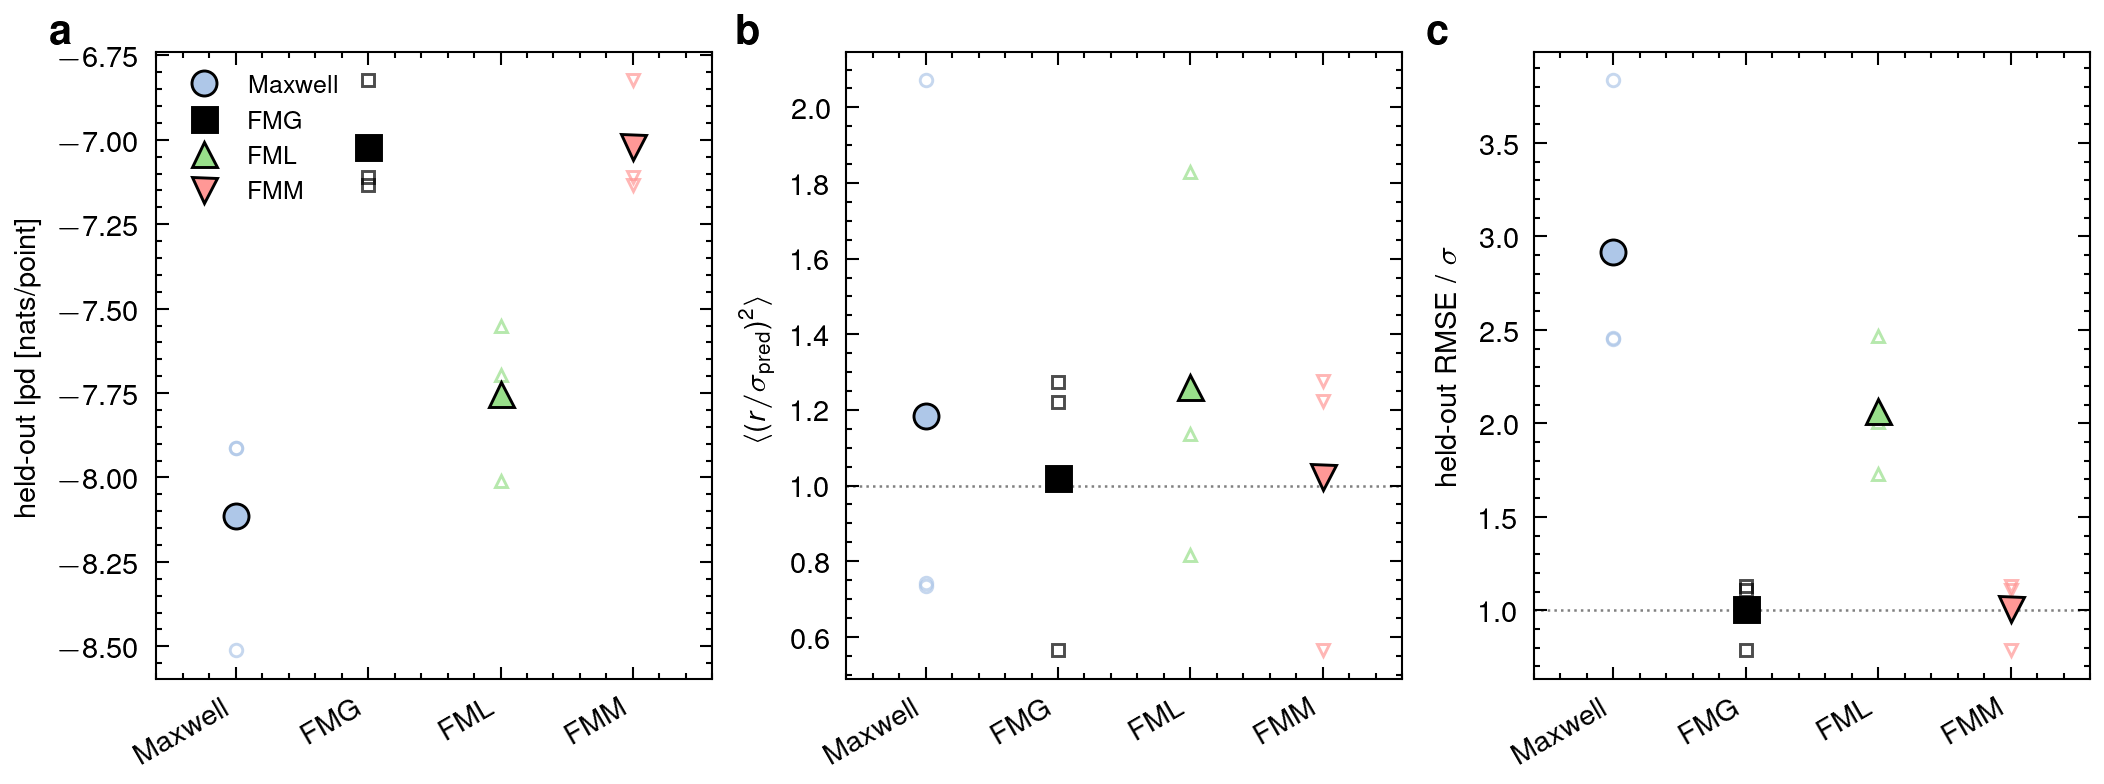

In [12]:
"""
plot_loto_predictive.py
========================
Leave-one-temperature-out model selection, from the `fmm_loto.json`
bundle Sec. 9c of `01_synthetic_fmm_tts.ipynb` writes. Same fixed
two-column width (7.0in) and font sizes as every other figure in this
notebook. No import of `paper_utils`, `rheogp`, or `torch`.

This is the selection rule that needs none of the assumptions the
in-sample criteria need. It does not count N, so the dense sampling
cannot inflate it; it needs no complexity penalty, because a model that
overfits predicts a withheld temperature WORSE and is punished by the
score itself; it needs no known noise level, unlike the weighted-RSS
columns; and it invokes no asymptotics, so FMG sitting at the boundary
beta = 0 of FMM costs it nothing.

What is withheld is a whole RECORD, not scattered points. The
correlation that breaks the pointwise criteria is correlation within a
chirp, so a held-out point surrounded by fitted neighbours is nearly
free to predict and would make the check vacuous. A held-out
temperature is not free: the model has to get the shift factor and the
constitutive law right at a temperature it never saw. Its a_T is
interpolated between the two fitted neighbours, with no WLF or
Arrhenius form imposed.

Panels: (a) mean log predictive density on the held-out record, HIGHER
is better, with the individual folds drawn as open markers around the
mean -- the spread across folds is the honest error bar on the
selection; (b) the calibration of the predicted uncertainty, mean
(residual / predictive std)^2, where one is calibrated, above one
overconfident and below one underconfident; (c) held-out RMSE in units
of the injected noise, so one means the model predicts an unseen
temperature as well as the noise floor allows.

Edit LOTO_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
LOTO_PATH = f"{DATA_DIR}/fmm_loto.json"
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/fmm_loto_predictive"

if not os.path.exists(LOTO_PATH):
    raise SystemExit(
        f"{LOTO_PATH} not found -- run Sec. 9c of "
        f"01_synthetic_fmm_tts.ipynb with RUN_LOTO = True first.")

with open(LOTO_PATH) as fh:
    bundle = json.load(fh)

rows = bundle["rows"]
candidates = bundle.get("candidates") or sorted({r["model"] for r in rows})
display = bundle.get("display_names", {})
true_model = bundle.get("true_model")
levels = sorted({r["noise_frac"] for r in rows})


def disp(name):
    return display.get(name, name)


try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})


def add_panel_letter(ax, text, xoff=-20, yoff=9, fontsize=10):
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


TAB20 = plt.cm.tab20.colors
MARKERS = ["o", "s", "^", "v", "D", "P", "X", "*", "h", "8"]


def candidate_style(name):
    """Fixed (color, marker, lw) per candidate -- the true generating
    model always black and heavier, matching every other figure here."""
    i = candidates.index(name)
    if name == true_model:
        return "k", MARKERS[i % len(MARKERS)], 1.6
    return TAB20[(2 * i + 1) % len(TAB20)], MARKERS[i % len(MARKERS)], 1.0


def get(nf, name):
    for r in rows:
        if r["model"] == name and abs(r["noise_frac"] - nf) < 1e-12:
            return r
    return None


# The candidates sit on a categorical axis rather than a numeric one:
# with a single noise level there is nothing to plot against, and with
# several the grouping stays readable.
x = np.arange(len(candidates), dtype=float)
# a small horizontal offset per noise level so groups do not overlap
off = (np.arange(len(levels)) - (len(levels) - 1) / 2.0) * 0.16

PANELS = [("lpd", r"held-out lpd [nats/point]", None),
          ("z2", r"$\langle (r/\sigma_{\mathrm{pred}})^2 \rangle$", 1.0),
          ("rmse_over_sigma", r"held-out RMSE / $\sigma$", 1.0)]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.6))

for j, (ax, (key, ylab, ref)) in enumerate(zip(axs, PANELS)):
    for li, nf in enumerate(levels):
        for ci, name in enumerate(candidates):
            r = get(nf, name)
            if r is None:
                continue
            color, marker, lw = candidate_style(name)
            # every fold, so the spread across held-out temperatures is
            # visible rather than hidden inside the mean
            fv = [f[key] if key in f
                  else f["rmse"] / r["sigma_true"] for f in r["folds"]]
            ax.plot(np.full(len(fv), x[ci] + off[li]), fv, marker=marker,
                    ms=3.0, lw=0.0, mfc="none", mec=color, mew=0.7,
                    alpha=0.7, zorder=2)
            mv = (r[key] if key in r
                  else r["rmse"] / r["sigma_true"])
            ax.plot([x[ci] + off[li]], [mv], marker=marker, ms=6.0, lw=0.0,
                    mfc=color, mec="k", mew=0.7, zorder=4,
                    label=disp(name) if li == 0 and j == 0 else None)
    if ref is not None:
        ax.axhline(ref, color="0.5", lw=0.6, ls=":", zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels([disp(c) for c in candidates], rotation=30,
                       ha="right")
    ax.set_xlim(-0.6, len(candidates) - 0.4)
    ax.set_ylabel(ylab)
    add_panel_letter(ax, r"$\mathbf{" + "abc"[j] + r"}$")
axs[0].legend(frameon=False, loc="best")

# ------------------------------------------------------------------ #
#  printed table                                                      #
# ------------------------------------------------------------------ #
print(f"true generating model: {disp(true_model)} ({true_model})")
print(f"{bundle.get('n_folds', '?')} held-out temperatures per candidate, "
      f"interior only (a_T interpolated between fitted neighbours)\n")

for nf in levels:
    sub = [r for r in rows if abs(r["noise_frac"] - nf) < 1e-12]
    print("=" * 84)
    print(f"noise {nf:.0%}    sigma = {sub[0]['sigma_true']:.2f} Pa"
          f"    held-out T = "
          f"{[f['T_heldout'] for f in sub[0]['folds']]}")
    hdr = (f"{'model':<26}{'lpd':>11}{'+- sem':>9}{'z2':>9}"
           f"{'rmse [Pa]':>12}{'rmse/sigma':>12}")
    print(hdr); print("-" * len(hdr))
    for r in sorted(sub, key=lambda r: -r["lpd"]):
        mark = " *" if r["model"] == true_model else "  "
        print(f"{disp(r['model']) + mark:<26}{r['lpd']:>11.4f}"
              f"{r['lpd_sem']:>9.4f}{r['z2']:>9.3f}{r['rmse']:>12.1f}"
              f"{r['rmse'] / r['sigma_true']:>12.3f}")
    ranked = sorted(sub, key=lambda r: -r["lpd"])
    win, runner = ranked[0], ranked[1]
    gap = win["lpd"] - runner["lpd"]
    # the spread across folds is the only error bar available on the gap
    sem = float(np.hypot(win["lpd_sem"], runner["lpd_sem"]))
    print(f"\n  selected by held-out lpd: {disp(win['model'])}"
          f"{'  (CORRECT)' if win['model'] == true_model else '  (wrong)'}")
    print(f"  margin over {disp(runner['model'])}: {gap:.4f} nats/point"
          f"  (fold-to-fold sem of the difference ~ {sem:.4f})")
    if not np.isfinite(sem):
        # a single fold gives a margin but no scatter to judge it against,
        # so the selection is unresolved regardless of how large the gap is
        print("  -> only ONE fold: the margin has no error bar, so this is "
              "not yet a selection.\n     Raise LOTO_N_FOLDS to at least 3.")
    elif gap < 2.0 * sem:
        print("  -> WITHIN the fold-to-fold scatter: this is a tie, not a "
              "selection. Raise LOTO_N_FOLDS.")
    else:
        print("  -> outside the fold-to-fold scatter.")

print("\nReading the panels: (a) higher is better and carries the selection; "
      "(b) one means the\npredicted uncertainty is honest -- a model far above "
      "one is overconfident, which\nmatters because (a) rewards honest "
      "uncertainty; (c) one means the model predicts an\nunseen temperature "
      "as well as the noise floor allows.")

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"\nwrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display as _display
    _display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)


 nominal   sd injected   sd realized   sd inferred    ratio  frac inferred
--------------------------------------------------------------------------
     3%        98.967        98.883        104.42    1.055         3.17%
     8%        263.91        265.27        267.64    1.014         8.11%
    15%        494.84        490.15        491.55    0.993        14.90%
    25%        824.73         819.7        821.37    0.996        24.90%
'sd realized' is the noise actually drawn (finite-sample), 'sd injected' the nominal std it was drawn from.
wrote fmm_figures/fmm_noise_inferred_vs_real.pdf and fmm_figures/fmm_noise_inferred_vs_real.png


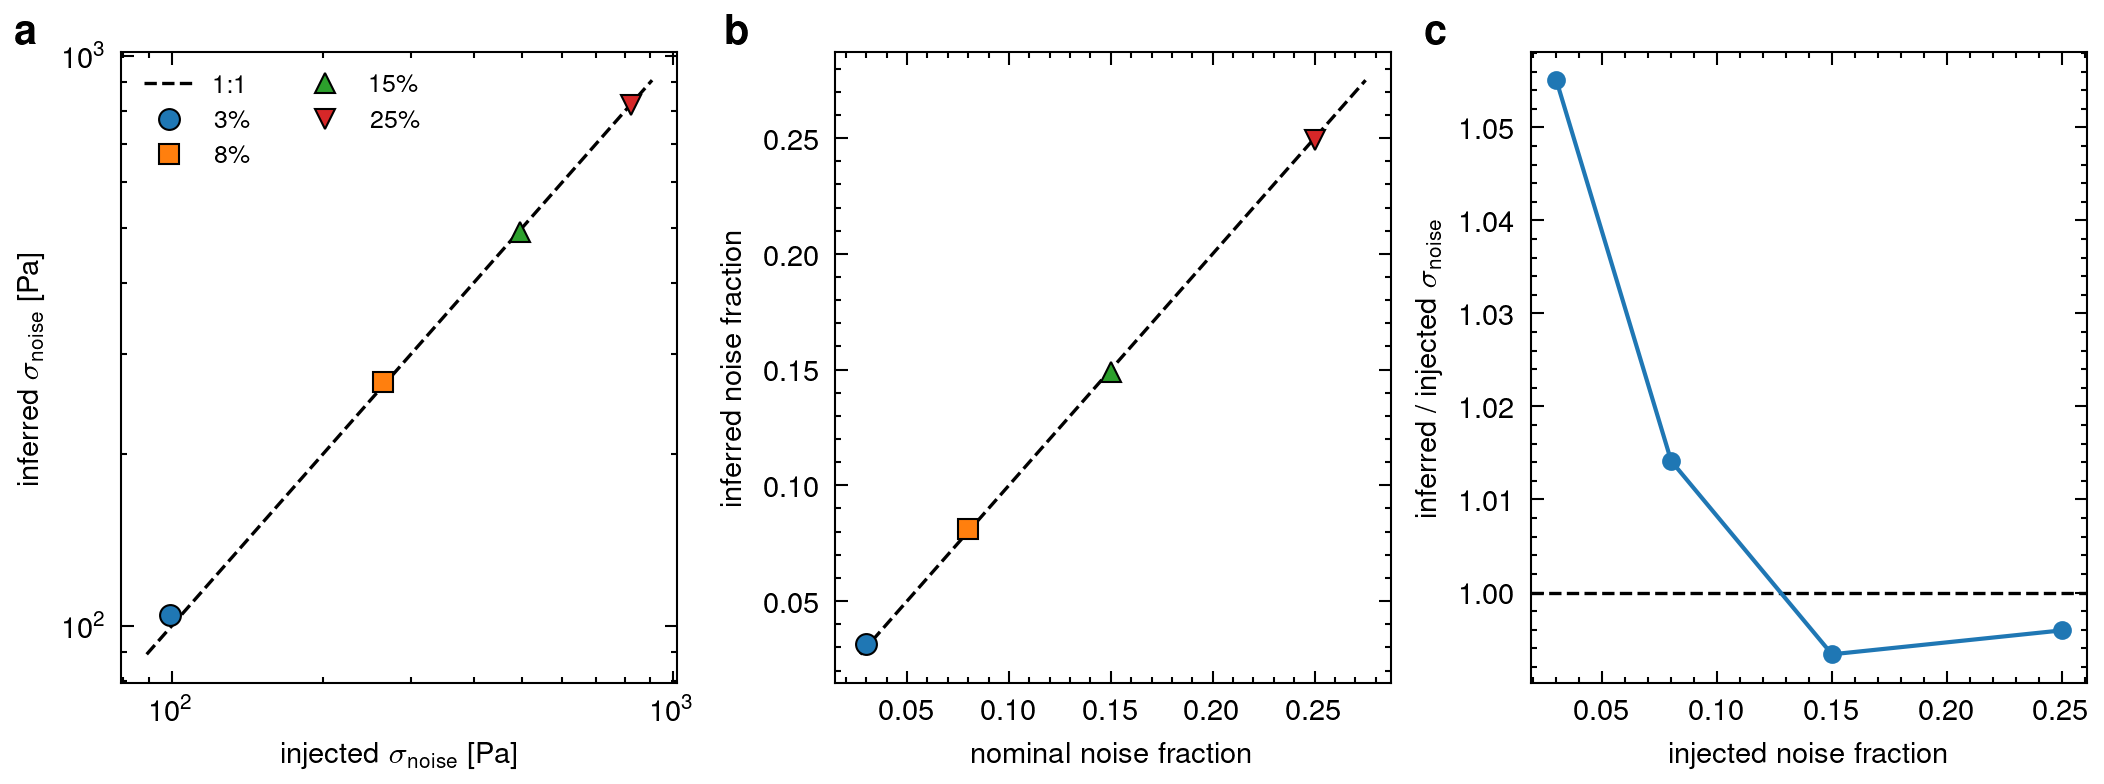

In [13]:
"""
plot_noise_inferred_vs_real.py
===============================
Does the GP recover the measurement noise it was actually given? From
the `export_noise_sweep()` bundle written by Sec. 9 of
`01_synthetic_fmm_tts.ipynb` (`fmm_noise_sweep.json`). The generator
knows exactly how much noise it injected into each chirp; the fit
learns a Gaussian-likelihood variance of its own, converted back to
stress units through the target scaler. Agreement between the two says
the fit is attributing the right share of the signal to measurement
noise rather than absorbing it into the constitutive parameters.

Left: inferred vs. injected noise standard deviation, against the 1:1
line. Middle: the same comparison as a noise FRACTION (inferred noise
sd divided by the pooled clean-stress sd) against the nominal fraction
the data were generated with. Right: the ratio inferred/injected vs.
noise level, against unity -- the residual bias, magnified.

Same fixed two-column width (7.0in) and font sizes as every other
figure in this notebook. No import of `paper_utils`, `rheogp`, or
`torch`.

Edit EXPORT_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
EXPORT_PATH = f"{DATA_DIR}/fmm_noise_sweep"
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/fmm_noise_inferred_vs_real"

with open(f"{EXPORT_PATH}.json") as fh:
    bundle = json.load(fh)

rows = sorted(bundle["rows"], key=lambda r: r["noise_frac"])
noise = np.array([r["noise_frac"] for r in rows], float)


def nz(key):
    return np.array([float(r["noise"][key]) for r in rows], float)


sd_true = nz("sd_true")
sd_realized = nz("sd_realized")
sd_inferred = nz("sd_inferred")
frac_nominal = nz("noise_frac_nominal")
frac_inferred = nz("frac_inferred")
ratio = nz("sd_ratio")

try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})


# yoff lifts the letter clear of the topmost y tick label, which in
# this figure's narrow panels sits at the same height as the letter
def add_panel_letter(ax, text, xoff=-20, yoff=9, fontsize=10):
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


TAB20 = plt.cm.tab20.colors
MARKERS = ["o", "s", "^", "v", "D", "P", "X", "*", "h", "8"]


def level_style(i):
    return TAB20[(2 * i) % len(TAB20)], MARKERS[i % len(MARKERS)]


fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(7.0, 2.6))

# ---- (a) inferred vs. injected noise sd, in stress units -------------
lo = 0.9 * min(sd_true.min(), sd_inferred.min())
hi = 1.1 * max(sd_true.max(), sd_inferred.max())
axA.plot([lo, hi], [lo, hi], color="k", ls="--", lw=0.8, zorder=1, label="1:1")
for i, n in enumerate(noise):
    c, m = level_style(i)
    axA.plot(sd_true[i], sd_inferred[i], marker=m, ms=5, lw=0.0, color=c,
             mec="k", mew=0.5, zorder=3, label=rf"${100 * n:.0f}\%$")
axA.set_xscale("log"); axA.set_yscale("log")
axA.set_xlabel(r"injected $\sigma_{\mathrm{noise}}$ [Pa]")
axA.set_ylabel(r"inferred $\sigma_{\mathrm{noise}}$ [Pa]")
axA.legend(frameon=False, loc="best", ncol=2)
add_panel_letter(axA, r"$\mathbf{a}$")

# ---- (b) the same, as a noise fraction ------------------------------
flo = 0.9 * min(frac_nominal.min(), frac_inferred.min())
fhi = 1.1 * max(frac_nominal.max(), frac_inferred.max())
axB.plot([flo, fhi], [flo, fhi], color="k", ls="--", lw=0.8, zorder=1)
for i in range(len(noise)):
    c, m = level_style(i)
    axB.plot(frac_nominal[i], frac_inferred[i], marker=m, ms=5, lw=0.0,
             color=c, mec="k", mew=0.5, zorder=3)
axB.set_xlabel(r"nominal noise fraction")
axB.set_ylabel(r"inferred noise fraction")
add_panel_letter(axB, r"$\mathbf{b}$")

# ---- (c) the residual bias ------------------------------------------
axC.axhline(1.0, color="k", ls="--", lw=0.8, zorder=1)
axC.plot(noise, ratio, marker="o", ms=3.5, lw=1.0, color="tab:blue", zorder=3)
axC.set_xlabel(r"injected noise fraction")
axC.set_ylabel(r"inferred / injected $\sigma_{\mathrm{noise}}$")
add_panel_letter(axC, r"$\mathbf{c}$")

hdr = (f"{'nominal':>8} {'sd injected':>13} {'sd realized':>13} "
       f"{'sd inferred':>13} {'ratio':>8} {'frac inferred':>14}")
print(hdr); print("-" * len(hdr))
for i, n in enumerate(noise):
    print(f"{n:>7.0%} {sd_true[i]:>13.5g} {sd_realized[i]:>13.5g} "
          f"{sd_inferred[i]:>13.5g} {ratio[i]:>8.3f} {frac_inferred[i]:>13.2%}")
print("'sd realized' is the noise actually drawn (finite-sample), "
      "'sd injected' the nominal std it was drawn from.")

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display as _display
    _display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)

In [14]:
"""
run_mastercurve_comparison.py
==============================
Build the SAME master curve a second way -- with the `mastercurves`
package (Lennon, McKinley & Swan, PNAS 2023) instead of rheogp's joint
fit -- and fit both with `pyRheo`, so the two routes can be compared
end to end. Writes one `<CMP_PATH>.json`/`.npz` bundle; the cell after
this one plots it and needs neither package.

The two routes are genuinely independent. rheogp infers a_T as fitted
parameters of one constitutive model applied jointly to every chirp:
shifts and physics come out together. `mastercurves` superposes the
data with Gaussian process regression and maximum a posteriori
estimation and assumes no constitutive model at all, so a_T is its
only output. Agreement is evidence for both; disagreement says the
superposition step is where they part.

What is superposed
------------------
SHIFT_KIND selects the curve handed to `mastercurves`. The default is
**tan(delta) = G''/G'**, which is invariant to any vertical shift b_T,
so superposing it horizontally recovers a_T without vertical-shift
contamination; "gstar" superposes |G*| instead, which carries the
modulus scale and therefore assumes b_T = 1 unless VERTICAL is on.
Either way the a_T that comes out is then applied to G' AND G'' to
build the master curve -- the shifted quantity is only the vehicle for
finding the shifts.

Requires `pip install mastercurves pyRheo` (only this cell does; the
plotting cell below is pure numpy/json). The RAW FFT spectra go to the
package as-is -- every point, unbinned, and for |G*| with nothing
filtered out, since |G*| is positive by construction and needs no
positivity cut before its logarithm.
"""
import numpy as np

# Re-read mastercurve_compare.py on every run; see the plotting cell.
import importlib
import mastercurve_compare
importlib.reload(mastercurve_compare)

from mastercurve_compare import (
    spectra_for_superposition, run_mastercurves, overlap_report,
    build_master_curve_raw, fit_pyrheo, fmm_quasiproperties,
    export_mastercurve_comparison,
)

# ---------------------------- USER SETTINGS ----------------------------
# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
EXPORT_PATH = f"{DATA_DIR}/fmm_export"     # the export_master_curve() bundle to re-shift
CMP_PATH = f"{DATA_DIR}/fmm_mccompare"           # written: <CMP_PATH>.json + <CMP_PATH>.npz
SHIFT_KIND = "gstar"           # what gets superposed to FIND a_T:
                               #   "gstar"    |G*| = sqrt(G'^2 + G''^2)
                               #   "tandelta" G''/G'
                               #   "gp"/"gdp" G' or G'' alone
                               # a_T is then applied to G' AND G'' either way
                               # -- the superposed quantity is only the vehicle
                               # for finding the shifts. Note |G*| carries the
                               # modulus scale, so shifting it horizontally
                               # alone assumes b_T = 1; tan(delta) is immune to
                               # b_T, so it is the safer cross-check if the two
                               # disagree. Set VERTICAL=True to fit b_T too.
VERTICAL = False               # also fit a vertical shift b_T
N_BINS = "auto"                # Binning applies ONLY to finding a_T. The
                               # mastercurves GP is exact per state and goes
                               # singular on a dense linearly-spaced omega grid
                               # (on the raw DGEBA spectra it emitted 11472
                               # overflow warnings and its a_T came out ~0.5
                               # decades WORSE), so "auto" keeps the most
                               # points per state that stay well-conditioned.
                               # The DATA PRESENTED is never binned: the master
                               # curves below are built by build_master_curve_raw()
                               # from every raw FFT point, with these a_T applied.
                               # None forces the raw (ill-conditioned) fit; an
                               # integer forces a specific binning.
PYRHEO_MODEL = None            # None -> the bundle's own model_name
PYRHEO_KW = dict(initial_guesses="random", num_initial_guesses=64,
                 minimization_algorithm="Powell")
# -----------------------------------------------------------------------

spec, values, qlabel = spectra_for_superposition(
    EXPORT_PATH, shift_kind=SHIFT_KIND, n_bins=N_BINS)
print(f"{EXPORT_PATH}: {len(spec['omega'])} records, "
      f"T = {spec['temps'].min():g}..{spec['temps'].max():g} C, "
      f"reference T = {spec['T_ref']:g} C, model = {spec['model_name']}")
# raw -> positive (G' and G'' both > 0, needed before taking logs) ->
# used. Printed per record so any thinning is visible, never silent.
print(f"{'T [C]':>7} {'raw':>6} {'positive':>9} {'used':>6}")
for T, (n_raw, n_pos, n_use) in zip(spec["temps"], spec["point_counts"]):
    flag = "  <- binned" if n_use < n_pos else ""
    print(f"{T:>7g} {n_raw:>6d} {n_pos:>9d} {n_use:>6d}{flag}")

print(f"\nsuperposing {SHIFT_KIND} horizontally"
      + (" and vertically" if VERTICAL else "")
      + f" across {len(spec['temps'])} temperatures ...")
mcres = run_mastercurves(spec["omega"], values, spec["temps"],
                         spec["i_ref"], vertical=VERTICAL)

# Which states are actually pinned down by overlap, and which are not.
# Pairwise superposition chains its shifts, so a barely-overlapping pair
# leaves its own shift loose and passes that looseness down the chain --
# this says which temperature to distrust when the two routes disagree.
overlap_report(spec["omega"], mcres["aT"], spec["temps"])

# The SAME raw spectra, shifted two different ways. Note these are built
# from the FULL RAW spectra regardless of what N_BINS did above: binning
# (if any) is a numerical requirement of the step that FINDS a_T, not a
# property of the comparison. Once a_T is known it is one number per
# record, and it belongs on every measured point -- which also keeps
# this figure consistent with the master curve plotted elsewhere in this
# notebook from the same export.
curve_ours = build_master_curve_raw(EXPORT_PATH, spec["temps"], spec["aT_rheogp"])
curve_mc = build_master_curve_raw(EXPORT_PATH, spec["temps"], mcres["aT"])
print(f"\napplied a_T to G' and G'' -> master curves of "
      f"{curve_ours['omega'].size} points "
      f"(rheogp shifts) and {curve_mc['omega'].size} points "
      f"(mastercurves shifts)")

# The SAME constitutive model fitted to each, by the same package with
# the same settings -- so the parameter gap is attributable to the
# superposition step and nothing else.
model = PYRHEO_MODEL or spec["model_name"]
print(f"\nfitting {model} with pyRheo to the rheogp-shifted master curve ...")
fit_ours = fit_pyrheo(curve_ours["omega"], curve_ours["Gp"], curve_ours["Gdp"],
                      model, **PYRHEO_KW)
print(f"fitting {model} with pyRheo to the mastercurves-shifted master curve ...")
fit_mc = fit_pyrheo(curve_mc["omega"], curve_mc["Gp"], curve_mc["Gdp"],
                    model, **PYRHEO_KW)

# rheogp's own analytic parameters, expressed in pyRheo's
# quasi-property convention -- the reference both fitted columns should
# sit near. Exact only for the Fractional Maxwell family, and the
# conversion self-checks against rheogp's own G*(w) before returning.
extra = {}
if model in ("FractionalMaxwell", "FractionalMaxwellGel"):
    pp = spec["phys_params"]
    gc = spec["prefactors"]["Gc"]["scalar_mean"]
    extra["rheogp_quasiproperties"] = fmm_quasiproperties(
        gc, pp["alpha"], pp.get("beta", 0.0), pp["tau_c"])
    print("\nrheogp's own parameters in pyRheo units: "
          + ", ".join(f"{k}={v:.5g}" for k, v in
                      extra["rheogp_quasiproperties"].items()
                      if isinstance(v, float)))

export_mastercurve_comparison(
    CMP_PATH, spec, mcres, curve_mc, curve_ours, fit_mc, fit_ours,
    shift_kind=SHIFT_KIND, shift_values=values, extra=extra or None,
)

  n_bins= 48 ->  30 points/state: well-conditioned
fmm_export/fmm_export: 9 records, T = 30..90 C, reference T = 50 C, model = FractionalMaxwell
  T [C]    raw  positive   used
     30     61        61     30  <- binned
     40     61        61     30  <- binned
     45     61        61     30  <- binned
     50     61        61     30  <- binned
     55     61        61     30  <- binned
     60     61        61     30  <- binned
     70     61        61     30  <- binned
     80     61        61     30  <- binned
     90     61        61     30  <- binned

superposing gstar horizontally across 9 temperatures ...
  states handed to MasterCurve (T [C]): ['30', '40', '45', '50', '55', '60', '70', '80', '90']
  points per state: [30, 30, 30, 30, 30, 30, 30, 30, 30]
  mastercurves: superposed 9 states, loss = -1000.81, reference T = 50
  a_T range: 0.01093 .. 22.53 (3.31 decades)
  adjacent-pair overlap [decades], median 1.39:
       30 - 40    C :   1.09   <- least overlap, shift least d

/Users/isaacmirandavaldez/anaconda3/envs/rheogp/lib/python3.10/site-packages/pyRheo/rheo_models/oscillation_models.py:208: RuntimeWarning: divide by zero encountered in scalar power
  G_c = V * (tau_c ** (-alpha))
/Users/isaacmirandavaldez/anaconda3/envs/rheogp/lib/python3.10/site-packages/pyRheo/rheo_models/oscillation_models.py:212: RuntimeWarning: divide by zero encountered in power
  omega_tau_c_alpha_minus_beta = omega_tau_c ** (alpha - beta)
/Users/isaacmirandavaldez/anaconda3/envs/rheogp/lib/python3.10/site-packages/pyRheo/rheo_models/oscillation_models.py:213: RuntimeWarning: divide by zero encountered in power
  omega_tau_c_2_alpha_minus_beta = omega_tau_c ** (2 * (alpha - beta))
/Users/isaacmirandavaldez/anaconda3/envs/rheogp/lib/python3.10/site-packages/pyRheo/rheo_models/oscillation_models.py:227: RuntimeWarning: invalid value encountered in multiply
  G_prime = G_c * (numerator_G_prime / denominator)
/Users/isaacmirandavaldez/anaconda3/envs/rheogp/lib/python3.10/site-packa

Iterations used: 12
Best initial guess was: [27999022.23688698, 762435.2702016926, 0.1677903300509398, 0.045501171906886906]
Consider replacing the beta springpot element with a spring.
  pyRheo [FractionalMaxwell]: G=46525, V=57995, alpha=0.76803, beta=1.6323e-09, Cost=103.8
  pyRheo [FractionalMaxwell]: MAPE = 17.94%, log-RMSE = 0.3774
fitting FractionalMaxwell with pyRheo to the mastercurves-shifted master curve ...
  pyRheo: fitting 540 of 549 points (1.6% dropped: non-positive G' or G'', which pyRheo cannot take a log of)
Iterations used: 4
Iterations used: 4
Iterations used: 10
Iterations used: 17
Iterations used: 8


/Users/isaacmirandavaldez/anaconda3/envs/rheogp/lib/python3.10/site-packages/pyRheo/rheo_models/oscillation_models.py:211: RuntimeWarning: divide by zero encountered in power
  omega_tau_c_2alpha_minus_beta = omega_tau_c ** (2 * alpha - beta)


Best initial guess was: [28998195.183785304, 20821939.72187128, 0.18596065086606317, 0.024770455694465995]
Consider replacing the beta springpot element with a spring.
  pyRheo [FractionalMaxwell]: G=45599, V=58544, alpha=0.79439, beta=2.2311e-09, Cost=119.06
  pyRheo [FractionalMaxwell]: MAPE = 20.10%, log-RMSE = 0.4048

rheogp's own parameters in pyRheo units: G=49978, V=50188, alpha=0.65025, beta=4.1927e-05
exported comparison -> fmm_export/fmm_mccompare.json + fmm_export/fmm_mccompare.npz


('fmm_export/fmm_mccompare.json', 'fmm_export/fmm_mccompare.npz')

1) SHIFT FACTORS
   T [C]     aT rheogp   aT mastercurves   log10 ratio
      30        33.098            22.534       -0.1670
      40        4.9686            4.7761       -0.0172
      45        2.1369            2.1118       -0.0051
      50             1                 1        0.0000
      55       0.48698           0.49011        0.0028
      60       0.25017           0.25243        0.0039
      70      0.075477          0.076754        0.0073
      80      0.026486          0.027328        0.0136
      90       0.01051          0.010928        0.0169
RMS disagreement: 0.0565 decades
wrote fmm_figures/fig_mc_fmm_shift_factors.pdf and fmm_figures/fig_mc_fmm_shift_factors.png

2) MASTER CURVES
  G': median |mc - ours| = 1.85%, max = 21.14%
  G'': median |mc - ours| = 6.49%, max = 18.67%
wrote fmm_figures/fig_mc_fmm_master_curve.pdf and fmm_figures/fig_mc_fmm_master_curve.png

3) PARAMETERS (table only)
pyRheo model: FractionalMaxwell
   parameter     rheogp curve     mastercurve

{'ours': {'G': 46524.75600365134,
  'V': 57994.79968699793,
  'alpha': 0.7680277888156719,
  'beta': 1.6323437289305355e-09,
  'Cost': 103.80407559486359},
 'mastercurves': {'G': 45598.974255216846,
  'V': 58543.834692684686,
  'alpha': 0.7943934708391042,
  'beta': 2.2311265757338437e-09,
  'Cost': 119.06233620927505}}

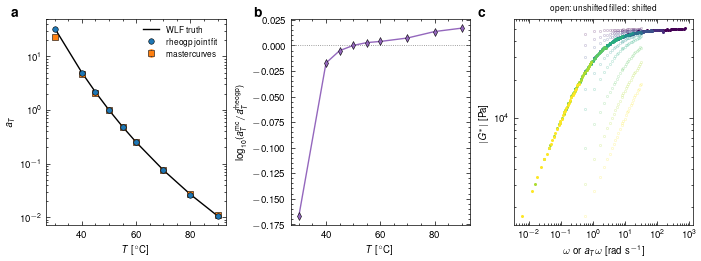

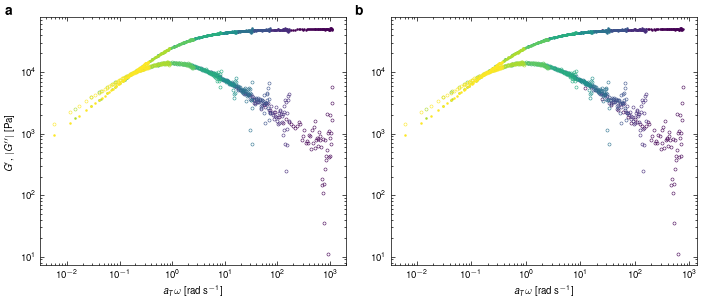

In [15]:
"""
plot_mastercurve_comparison.py
===============================
The three comparison figures, from the `<CMP_PATH>.json`/`.npz` bundle
the cell above writes. Pure numpy + json + matplotlib on this side --
neither `mastercurves` nor `pyRheo` is imported here, so these figures
re-render on any machine that has the bundle.

  1. shift factors   a_T from rheogp's joint fit vs. from the
                     `mastercurves` package (vs. the WLF ground truth,
                     for the synthetic set), their disagreement in
                     decades, and the collapse the package achieved on
                     the quantity it superposed.
  2. master curves   the same raw G'/G'' spectra under each route's own
                     shifts, each with its pyRheo fit, the two fits
                     overlaid, and their relative difference per decade.
  3. parameters      printed as a table, not plotted -- the pyRheo
                     exponents side by side against ground truth,
                     quasi-properties as a ratio, and each fit's own
                     residual, since a parameter gap only means
                     something if both fits describe their data.

Figures are drawn at this notebook's fixed two-column width (7.0in) and
font sizes, like every other figure here.
"""
import os
# Force a re-read of mastercurve_compare.py on every run. Without this,
# a kernel that imported the module earlier in the session keeps serving
# that stale copy, so edits to the figure code (sizes, dpi, panels) never
# reach the output and the cell appears not to have been fixed.
import importlib
import mastercurve_compare
importlib.reload(mastercurve_compare)

from mastercurve_compare import (
    plot_shift_factor_comparison,
    plot_master_curve_comparison,
    print_parameter_comparison,
)

# Every input this cell reads lives in one folder, the one
# 01_synthetic_fmm_tts.ipynb exports to.
DATA_DIR = "fmm_export"
CMP_PATH = f"{DATA_DIR}/fmm_mccompare"
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "fmm_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_PREFIX = f"{FIG_DIR}/fig_mc_fmm"

print("=" * 70, "\n1) SHIFT FACTORS\n" + "=" * 70)
plot_shift_factor_comparison(CMP_PATH, f"{OUT_PREFIX}_shift_factors")

print("\n" + "=" * 70, "\n2) MASTER CURVES\n" + "=" * 70)
plot_master_curve_comparison(CMP_PATH, f"{OUT_PREFIX}_master_curve")

# Printed, not plotted: the pyRheo fits stay in the exported bundle and
# their numbers stay visible here, but nothing about them is drawn.
print("\n" + "=" * 70, "\n3) PARAMETERS (table only)\n" + "=" * 70)
print_parameter_comparison(CMP_PATH)

In [16]:
import sys
print(sys.executable)
for m in ("mastercurves", "pyRheo"):
    try:
        __import__(m); print("ok      ", m)
    except ImportError:
        print("MISSING ", m)

/Users/isaacmirandavaldez/anaconda3/envs/rheogp/bin/python3.10
ok       mastercurves
ok       pyRheo


In [17]:
import sys
sys.modules.pop("mastercurve_compare", None)
import mastercurve_compare
print(mastercurve_compare.__file__, hasattr(mastercurve_compare, "spectra_for_superposition"))

/Users/isaacmirandavaldez/Documents/Misc/rheogp/demos/mastercurve_compare.py True
